# Unemployment Analysis with Python

### CodeAlpha Data Science Internship - Task 2

**Prepared by:** CodeAlpha Data Science Intern  
**Analysis period:** May 2019 - October 2020 (two datasets)  
**Primary dataset:** `Unemployment in India.csv`  
**Supplementary dataset:** `Unemployment_Rate_upto_11_2020.csv`

---

## Project overview

This notebook analyses monthly unemployment estimates for Indian states and
union territories. It cleans the raw data, explores national and regional
patterns, separates Rural and Urban labour markets, and studies the labour-market
shock associated with the COVID-19 period.

The central question is descriptive: **how did unemployment, employment and
labour participation change across places and periods, and what do those changes
imply for policy?** The notebook does not claim that COVID-19 was the sole cause
of every observed change.

## Objectives

1. Inspect both raw datasets without assuming their schema, types or date formats.
2. Clean and document data-quality decisions without arbitrary imputation.
3. Measure overall, state-level, area-level and monthly unemployment.
4. Examine estimated employment and labour participation.
5. Quantify the observed COVID-period change against an immediate pre-COVID baseline.
6. Check whether the data can support seasonal claims.
7. Translate findings into policy recommendations that are explicitly linked to results.

## Datasets and analytical design

| Dataset | Clean records | Regions | Months | Main contribution |
|---|---:|---:|---|---|
| **Dataset 1** - `Unemployment in India.csv` | 740 | 28 | 14 (May 2019-Jun 2020) | Primary: Rural/Urban detail, pre-COVID baseline, shock and early rebound |
| **Dataset 2** - `Unemployment_Rate_upto_11_2020.csv` | 267 | 27 | 10 (Jan-Oct 2020) | Supplementary: longer 2020 recovery window and geographic zones |

Dataset 1 has **two rows per region-month** (Rural and Urban). Dataset 2 has one
overall row per region-month, no area split, and additional zone/coordinate fields.
They are related views, not duplicate records. **They are analysed separately and
compared, never concatenated.**

The file named `Unemployment_Rate_upto_11_2020.csv` actually ends on **31 October
2020**; the observed date range is used throughout.

### Method note: two kinds of average

- **Unweighted mean** - every region-area-month observation has equal weight.
- **Labour-force-weighted rate** - derived as
  `sum(estimated unemployed) / sum(estimated labour force) x 100`, where
  `labour force = employed / (1 - unemployment rate/100)`.

The weighted measure prevents a small territory from having the same influence as
Uttar Pradesh. It is the headline measure, while the unweighted mean is retained
for transparency.

In [1]:
%matplotlib inline

import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import charts
import utils

utils.setup_plot_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print(f"Project root: {PROJECT_ROOT}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {plt.matplotlib.__version__} | seaborn {sns.__version__}")

Project root: C:\Users\My Pc\CodeAlpha_Unemployment_Analysis
pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2


The chart functions in `src/charts.py` save publication-quality PNGs to
`outputs/charts/` and return figures for inline display. The notebook therefore
produces the same charts as the reusable scripts.

## 1. Load the raw datasets

The raw files are loaded without renaming columns or coercing types. This exposes
the actual schema before any cleaning.

In [2]:
raw1 = utils.load_raw_dataset1()
raw2 = utils.load_raw_dataset2()

print("Dataset 1 shape:", raw1.shape)
print("Dataset 1 columns:", [repr(c) for c in raw1.columns])
display(raw1.head(5))

print("\nDataset 2 shape:", raw2.shape)
print("Dataset 2 columns:", [repr(c) for c in raw2.columns])
display(raw2.head(5))

Dataset 1 shape: (768, 7)
Dataset 1 columns: ["'Region'", "' Date'", "' Frequency'", "' Estimated Unemployment Rate (%)'", "' Estimated Employed'", "' Estimated Labour Participation Rate (%)'", "'Area'"]


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,"11,999,139.00",43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,"11,755,881.00",42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,"12,086,707.00",43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,"12,285,693.00",43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,"12,256,762.00",44.68,Rural



Dataset 2 shape: (267, 9)
Dataset 2 columns: ["'Region'", "' Date'", "' Frequency'", "' Estimated Unemployment Rate (%)'", "' Estimated Employed'", "' Estimated Labour Participation Rate (%)'", "'Region.1'", "'longitude'", "'latitude'"]


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.91,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.91,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.91,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.91,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.91,79.74


## 2. Dataset inspection

Inspection is performed separately for each file. Key raw findings are:

- **Dataset 1:** 768 rows, of which
  **28 are completely blank**. After
  removing blank rows there are **740 usable observations**.
  It has 28 regions, a Rural/Urban split, and 14 months from
  **2019-05-31** to **2020-06-30**.
- **Dataset 2:** 267 rows, no blank rows,
  **267 usable observations**, 27 regions,
  and 10 months from **2020-01-31** to
  **2020-10-31**.
- Column headers in both files contain **leading spaces** (for example
  `' Date'` and `' Estimated Unemployment Rate (%)'`). Dataset 1 dates also carry
  leading spaces; Frequency appears as `Monthly` in Dataset 1 and `M` in Dataset 2.
- Dataset 1 has 28 empty rows; the 27 apparent duplicate records are the repeated
  blank rows. There are **zero duplicate non-blank records**.
- Dataset 2 has three missing region-month combinations: Jammu & Kashmir in April
  2020, and Sikkim in January and February 2020. They remain absent rather than
  being imputed.

In [3]:
for label, frame, date_col in [
    ("Dataset 1", raw1, "Date"),
    ("Dataset 2", raw2, "Date"),
]:
    work = frame.copy()
    work.columns = [str(c).strip() for c in work.columns]
    parsed = pd.to_datetime(
        work[date_col].astype("string").str.strip(),
        format="%d-%m-%Y",
        errors="coerce",
    )
    print("=" * 75)
    print(label)
    print("=" * 75)
    print("Shape:", work.shape)
    print("Completely blank rows:", int(work.isna().all(axis=1).sum()))
    print("Exact duplicates (including blank):", int(work.duplicated().sum()))
    print("Duplicates after blank-row removal:", int(work.dropna(how="all").duplicated().sum()))
    print("Date range:", parsed.min().date(), "to", parsed.max().date())
    print("Regions:", work["Region"].dropna().nunique())
    display(work.isna().sum().to_frame("missing_count").T)
    display(work.describe().T)

Dataset 1
Shape: (768, 7)
Completely blank rows: 28
Exact duplicates (including blank): 27
Duplicates after blank-row removal: 0
Date range: 2019-05-31 to 2020-06-30
Regions: 28


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
missing_count,28,28,28,28,28,28,28


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),740.00,11.79,10.72,0.00,4.66,8.35,15.89,76.74
Estimated Employed,740.00,"7,204,460.03","8,087,988.43","49,420.00","1,190,404.50","4,744,178.50","11,275,489.50","45,777,509.00"
Estimated Labour Participation Rate (%),740.00,42.63,8.11,13.33,38.06,41.16,45.51,72.57


Dataset 2
Shape: (267, 9)
Completely blank rows: 0
Exact duplicates (including blank): 0
Duplicates after blank-row removal: 0
Date range: 2020-01-31 to 2020-10-31
Regions: 27


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
missing_count,0,0,0,0,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),267.00,12.24,10.80,0.50,4.84,9.65,16.75,75.85
Estimated Employed,267.00,"13,962,105.72","13,366,318.36","117,542.00","2,838,930.50","9,732,417.00","21,878,686.00","59,433,759.00"
Estimated Labour Participation Rate (%),267.00,41.68,7.85,16.77,37.27,40.39,44.05,69.69
longitude,267.00,22.83,6.27,10.85,18.11,23.61,27.28,33.78
latitude,267.00,80.53,5.83,71.19,76.09,79.02,85.28,92.94


### Inspection interpretation

The datasets are structurally different but complementary:

- Dataset 1 is the only source of **Rural/Urban** analysis and the only one with a
  pre-COVID period long enough to establish a baseline.
- Dataset 2 has a longer 2020 window and geographic zones, but no area split.
- The overlap is January-June 2020. A later validation cell shows that Dataset 1's
  derived rural+urban rate closely tracks Dataset 2's single regional rate, which
  supports the weighting method but does **not** justify merging the files.

The appropriate decision is therefore: **primary = Dataset 1, supplementary =
Dataset 2, no concatenation.**

## 3. Cleaning and preprocessing

Cleaning decisions are deliberately conservative:

1. Strip whitespace from column names and text values.
2. Remove only **completely empty rows** (28 in Dataset 1).
3. Parse dates with the explicit `dd-mm-yyyy` format and validate failures.
4. Convert numeric fields with coercion and check definitional ranges.
5. Check duplicates after standardisation.
6. Drop rows only if critical fields are missing - none were.
7. **Do not impute** missing region-months or replace zeros.
8. Retain 11 exact-zero unemployment observations and flag them.
9. Derive labour force and unemployed counts for weighted aggregation.

The derived fields are arithmetic identities, not new official estimates:
`labour force = employed / (1 - rate/100)` and `unemployed = labour force - employed`.

In [4]:
clean1, log1 = utils.clean_dataset1(raw1)
clean2, log2 = utils.clean_dataset2(raw2)

cleaning_summary = pd.DataFrame(
    [
        {
            "dataset": "Dataset 1",
            "raw_rows": log1["raw_shape"][0],
            "blank_rows_removed": log1["completely_blank_rows_removed"],
            "duplicates_removed": log1["duplicate_rows_removed"],
            "text_cells_cleaned": log1["text_cells_cleaned"],
            "zero_rates_retained": log1["zero_unemployment_rows_preserved"],
            "clean_rows": log1["cleaned_shape"][0],
            "regions": log1["regions"],
        },
        {
            "dataset": "Dataset 2",
            "raw_rows": log2["raw_shape"][0],
            "blank_rows_removed": log2["completely_blank_rows_removed"],
            "duplicates_removed": log2["duplicate_rows_removed"],
            "text_cells_cleaned": log2["text_cells_cleaned"],
            "zero_rates_retained": log2["zero_unemployment_rows_preserved"],
            "clean_rows": log2["cleaned_shape"][0],
            "regions": log2["regions"],
        },
    ]
)
display(cleaning_summary)
display(clean1.head(4))
display(clean2.head(4))

print("Dataset 1 missing cells after cleaning:", int(clean1.isna().sum().sum()))
print("Dataset 2 missing cells after cleaning:", int(clean2.isna().sum().sum()))

,dataset,raw_rows,blank_rows_removed,duplicates_removed,text_cells_cleaned,zero_rates_retained,clean_rows,regions
0,Dataset 1,768,28,0,1099,11,740,28
1,Dataset 2,267,0,0,534,0,267,27


,region,date,frequency,unemployment_rate,estimated_employed,labour_participation_rate,area,month,month_start,year,month_name,month_number,period,estimated_labour_force,estimated_unemployed,zero_unemployment
0,Andhra Pradesh,2019-05-31,Monthly,3.65,"11,999,139.00",43.24,Rural,2019-05,2019-05-01,2019,May,5,Pre-COVID,"12,453,699.01","454,560.01",False
1,Andhra Pradesh,2019-06-30,Monthly,3.05,"11,755,881.00",42.05,Rural,2019-06,2019-06-01,2019,Jun,6,Pre-COVID,"12,125,715.32","369,834.32",False
2,Andhra Pradesh,2019-07-31,Monthly,3.75,"12,086,707.00",43.50,Rural,2019-07,2019-07-01,2019,Jul,7,Pre-COVID,"12,557,617.66","470,910.66",False
3,Andhra Pradesh,2019-08-31,Monthly,3.32,"12,285,693.00",43.97,Rural,2019-08,2019-08-01,2019,Aug,8,Pre-COVID,"12,707,584.82","421,891.82",False


,region,date,frequency,unemployment_rate,estimated_employed,labour_participation_rate,zone,longitude,latitude,month,month_start,year,month_name,month_number,period,estimated_labour_force,estimated_unemployed,zero_unemployment
0,Andhra Pradesh,2020-01-31,Monthly,5.48,16635535,41.02,South,15.91,79.74,2020-01,2020-01-01,2020,Jan,1,Pre-COVID,"17,600,015.87","964,480.87",False
1,Andhra Pradesh,2020-02-29,Monthly,5.83,16545652,40.90,South,15.91,79.74,2020-02,2020-02-01,2020,Feb,2,Pre-COVID,"17,569,981.95","1,024,329.95",False
2,Andhra Pradesh,2020-03-31,Monthly,5.79,15881197,39.18,South,15.91,79.74,2020-03,2020-03-01,2020,Mar,3,Transition,"16,857,230.65","976,033.65",False
3,Andhra Pradesh,2020-04-30,Monthly,20.51,11336911,33.10,South,15.91,79.74,2020-04,2020-04-01,2020,Apr,4,COVID period,"14,262,059.38","2,925,148.38",False


Dataset 1 missing cells after cleaning: 0
Dataset 2 missing cells after cleaning: 0


In [5]:
quality = pd.read_csv(utils.CLEANED_DIR / "data_quality_report.csv")
display(quality)
print("Checks passed:", int((quality["status"] == "PASS").sum()), "of", len(quality))

,dataset,check,status,detail
0,Dataset 1,No duplicate region-date-area keys,PASS,0 duplicate keys
1,Dataset 2,No duplicate region-date keys,PASS,0 duplicate keys
2,Dataset 1,No missing critical values,PASS,0 missing critical cells
3,Dataset 2,No missing critical values,PASS,0 missing critical cells
4,Dataset 1,Unemployment rate within 0-100,PASS,range 0.00-76.74
5,Dataset 2,Unemployment rate within 0-100,PASS,range 0.50-75.85
6,Dataset 1,Labour participation rate within 0-100,PASS,range 13.33-72.57
7,Dataset 2,Labour participation rate within 0-100,PASS,range 16.77-69.69
8,Both,Derived labour force is positive,PASS,all derived labour-force estimates > 0
9,Dataset 1,Dates parsed,PASS,2019-05-31 to 2020-06-30


Checks passed: 15 of 15


### Cleaning result

- Dataset 1: **768 raw rows -> 740 clean
  observations**, 28 regions, two areas, 14 months.
- Dataset 2: **267 -> 267** observations,
  27 regions, 10 months.
- Dataset 1 has **44 missing region-area-months**
  out of an expected 784. They are not fabricated.
- Dataset 2 has **3 missing region-months** out of
  270.
- No duplicate non-blank records remain; all post-cleaning quality checks pass.
- Only **11 zero-rate observations** exist
  in Dataset 1; they are retained and flagged because they may reflect genuine
  small-area estimates or measurement noise. Removing them would bias the picture
  upward.

## 4. Exploratory data analysis

We now compute overall levels, state rankings, Rural/Urban differences, monthly
movement, employment and labour participation, and relationships among variables.

In [6]:
df1, df2 = utils.load_cleaned()

monthly_rows = []
for month, group in df1.groupby("month_start", sort=True):
    monthly_rows.append(
        {
            "month": group["month"].iloc[0],
            "n_obs": len(group),
            "unweighted_rate": group["unemployment_rate"].mean(),
            "weighted_rate": utils.weighted_rate(group),
            "median_rate": group["unemployment_rate"].median(),
            "p25": group["unemployment_rate"].quantile(0.25),
            "p75": group["unemployment_rate"].quantile(0.75),
            "avg_lpr": group["labour_participation_rate"].mean(),
        }
    )
monthly = pd.DataFrame(monthly_rows)
peak = monthly.loc[monthly["weighted_rate"].idxmax()]

overall_summary = pd.Series(
    {
        "observations": len(df1),
        "regions": df1["region"].nunique(),
        "months": df1["month"].nunique(),
        "weighted_unemployment_rate": utils.weighted_rate(df1),
        "unweighted_mean": df1["unemployment_rate"].mean(),
        "median": df1["unemployment_rate"].median(),
        "std_dev": df1["unemployment_rate"].std(),
        "minimum": df1["unemployment_rate"].min(),
        "maximum": df1["unemployment_rate"].max(),
        "average_lpr": df1["labour_participation_rate"].mean(),
        "zero_unemployment_observations": int(df1["zero_unemployment"].sum()),
    },
    name="value",
)
display(overall_summary.to_frame())
print(f"Peak weighted month: {peak['month']} at {peak['weighted_rate']:.2f}%")
display(monthly.round(2))

,value
observations,740.00
regions,28.00
months,14.00
weighted_unemployment_rate,9.94
unweighted_mean,11.79
median,8.35
std_dev,10.72
minimum,0.00
maximum,76.74
average_lpr,42.63


Peak weighted month: 2020-04 at 24.16%


,month,n_obs,unweighted_rate,weighted_rate,median_rate,p25,p75,avg_lpr
0,2019-05,54,8.87,7.04,6.87,3.66,12.50,43.90
1,2019-06,54,9.30,7.88,7.57,4.72,12.35,43.75
2,2019-07,54,9.03,7.37,7.16,3.79,12.16,43.71
3,2019-08,53,9.64,8.08,7.27,4.61,12.06,43.65
4,2019-09,52,9.05,7.08,6.24,4.38,12.12,44.30
5,2019-10,55,9.90,8.11,7.29,4.71,13.38,44.00
6,2019-11,55,9.87,7.25,6.94,4.39,14.30,44.11
7,2019-12,53,9.50,7.73,7.24,4.22,12.37,43.67
8,2020-01,53,9.95,7.24,6.79,4.29,13.68,44.05
9,2020-02,53,9.96,7.78,7.55,4.31,14.48,43.72


### Overall picture

Across all 740 region-area-month observations, the
**labour-force-weighted unemployment rate is 9.94%**.
The unweighted mean is 11.79%, the median is
8.35% and the standard deviation is 10.72 pp.
Observations range from 0.00% to 76.74%, so the
distribution is strongly right-skewed.

Before the shock, the weighted rate moved in a relatively narrow band around
7-8%. The highest weighted monthly value is **24.16% in
2020-04**; the unweighted mean that month is 23.64%.
The difference between weighted and unweighted measures is not an error: it reflects
how much weight large states receive.

In [7]:
state = (
    df1.assign(
        _unemployed=df1["estimated_unemployed"],
        _labour_force=df1["estimated_labour_force"],
    )
    .groupby("region")
    .agg(
        n_obs=("unemployment_rate", "size"),
        months_observed=("month", "nunique"),
        mean_rate=("unemployment_rate", "mean"),
        median_rate=("unemployment_rate", "median"),
        max_rate=("unemployment_rate", "max"),
        avg_lpr=("labour_participation_rate", "mean"),
        total_unemployed=("_unemployed", "sum"),
        total_labour_force=("_labour_force", "sum"),
    )
)
state["weighted_rate"] = state["total_unemployed"] / state["total_labour_force"] * 100
state = state.drop(columns=["total_unemployed", "total_labour_force"])
state = state.sort_values("weighted_rate", ascending=False)

print("Five highest average unemployment rates:")
display(state.head(5).round(2))
print("Five lowest average unemployment rates:")
display(state.tail(5).sort_values("weighted_rate").round(2))

Five highest average unemployment rates:


,n_obs,months_observed,mean_rate,median_rate,max_rate,avg_lpr,weighted_rate
region,,,,,,,
Tripura,28,14,28.35,27.31,43.64,61.82,28.04
Haryana,28,14,26.28,25.06,46.89,42.74,26.04
Jharkhand,28,14,20.58,17.28,70.17,41.67,17.74
Bihar,28,14,18.92,15.01,58.77,38.15,17.34
Delhi,28,14,16.50,15.02,45.78,38.93,17.05


Five lowest average unemployment rates:


,n_obs,months_observed,mean_rate,median_rate,max_rate,avg_lpr,weighted_rate
region,,,,,,,
Meghalaya,27,14,4.80,3.73,17.39,57.08,3.17
Assam,26,14,6.43,5.44,11.17,44.87,5.20
Odisha,28,14,5.66,3.87,24.48,38.93,5.75
Uttarakhand,27,14,6.58,5.56,17.36,33.78,5.86
Andhra Pradesh,28,14,7.48,5.40,32.30,39.38,6.29


### State-level differences

The highest labour-force-weighted averages are:

1. **Tripura: 28.04%**
2. **Haryana: 26.04%**
3. **Jharkhand: 17.74%**
4. **Bihar: 17.34%**
5. **Delhi: 17.05%**

The lowest are **Meghalaya (3.17%)**,
**Assam (5.20%)**,
**Odisha (5.75%)**,
**Uttarakhand (5.86%)** and
**Andhra Pradesh (6.29%)**.

This is a wide structural gap: Tripura's average is roughly nine times Meghalaya's.
A single national policy design would therefore be poorly targeted. Small states
and union territories with incomplete coverage (Chandigarh has 12 observations;
Assam, Goa, Jammu & Kashmir, Meghalaya, Puducherry, Sikkim and Uttarakhand also
have gaps) should be treated cautiously.

In [8]:
area_rows = []
for area, group in df1.groupby("area"):
    area_rows.append(
        {
            "area": area,
            "n_obs": len(group),
            "weighted_rate": utils.weighted_rate(group),
            "unweighted_mean": group["unemployment_rate"].mean(),
            "median": group["unemployment_rate"].median(),
            "average_lpr": group["labour_participation_rate"].mean(),
        }
    )
area_table = pd.DataFrame(area_rows).set_index("area")
display(area_table.round(2))

print("Monthly weighted rate by area:")
area_monthly = []
for (month, area), group in df1.groupby(["month", "area"]):
    area_monthly.append(
        {
            "month": month,
            "area": area,
            "weighted_rate": utils.weighted_rate(group),
        }
    )
display(pd.DataFrame(area_monthly).pivot(index="month", columns="area", values="weighted_rate").round(2))

,n_obs,weighted_rate,unweighted_mean,median,average_lpr
area,,,,,
Rural,359,9.36,10.32,6.76,44.46
Urban,381,11.18,13.17,9.97,40.90


Monthly weighted rate by area:


area,Rural,Urban
month,,
2019-05,6.31,8.59
2019-06,7.70,8.25
2019-07,6.92,8.34
2019-08,7.49,9.35
2019-09,5.91,9.57
2019-10,8.04,8.25
2019-11,6.46,8.90
2019-12,7.07,9.05
2020-01,6.08,9.72


### Rural versus Urban

Urban areas have a **higher average unemployment rate**:
**11.18% weighted (13.17% unweighted)**
versus **9.36% weighted (10.32% unweighted)**
in rural areas.

Labour participation is higher in rural areas:
**44.46% average LPR versus 40.90% urban**.
During the shock, both areas experienced similar absolute increases, but the rural
increase was larger relative to its lower base. Section 6 quantifies this.

### Relationships among numerical indicators

Pooled Pearson and Spearman correlations are computed across all region-area-month
observations. They describe association, not causation. State size and repeated
observations make pooled correlations difficult to interpret, so we also inspect
group-level summaries.

In [9]:
corr_cols = ["unemployment_rate", "estimated_employed", "labour_participation_rate"]
display(df1[corr_cols].corr(method="pearson").round(2))
print("Spearman:")
display(df1[corr_cols].corr(method="spearman").round(2))

monthly_employment_corr = monthly.set_index("month")["unweighted_rate"].corr(
    df1.groupby("month")["estimated_employed"].sum()
)
print(f"Monthly national unemployment vs reported employment correlation: {monthly_employment_corr:.2f}")

,unemployment_rate,estimated_employed,labour_participation_rate
unemployment_rate,1.00,-0.22,0.00
estimated_employed,-0.22,1.00,0.01
labour_participation_rate,0.00,0.01,1.00


Spearman:


,unemployment_rate,estimated_employed,labour_participation_rate
unemployment_rate,1.00,-0.22,-0.02
estimated_employed,-0.22,1.00,0.05
labour_participation_rate,-0.02,0.05,1.00


Monthly national unemployment vs reported employment correlation: -0.97


The pooled unemployment-employment correlation is only about **-0.22**, and the
unemployment-LPR correlation is essentially **0.00**. This does not mean the labour
market is disconnected: it reflects enormous variation in state population and
repeated measurements. At the national monthly level, unemployment and total
reported employment move much more strongly in opposite directions, because the
COVID shock simultaneously destroyed jobs and raised joblessness.

The practical lesson is that a simple correlation matrix is not sufficient for
policy targeting; state, area and period splits are essential.

## 5. Visualisations

All charts use a consistent theme, informative titles, labelled axes, a source note,
and 200-dpi PNG output. They are saved in `outputs/charts/`.

### 5.1 National trend and state ranking

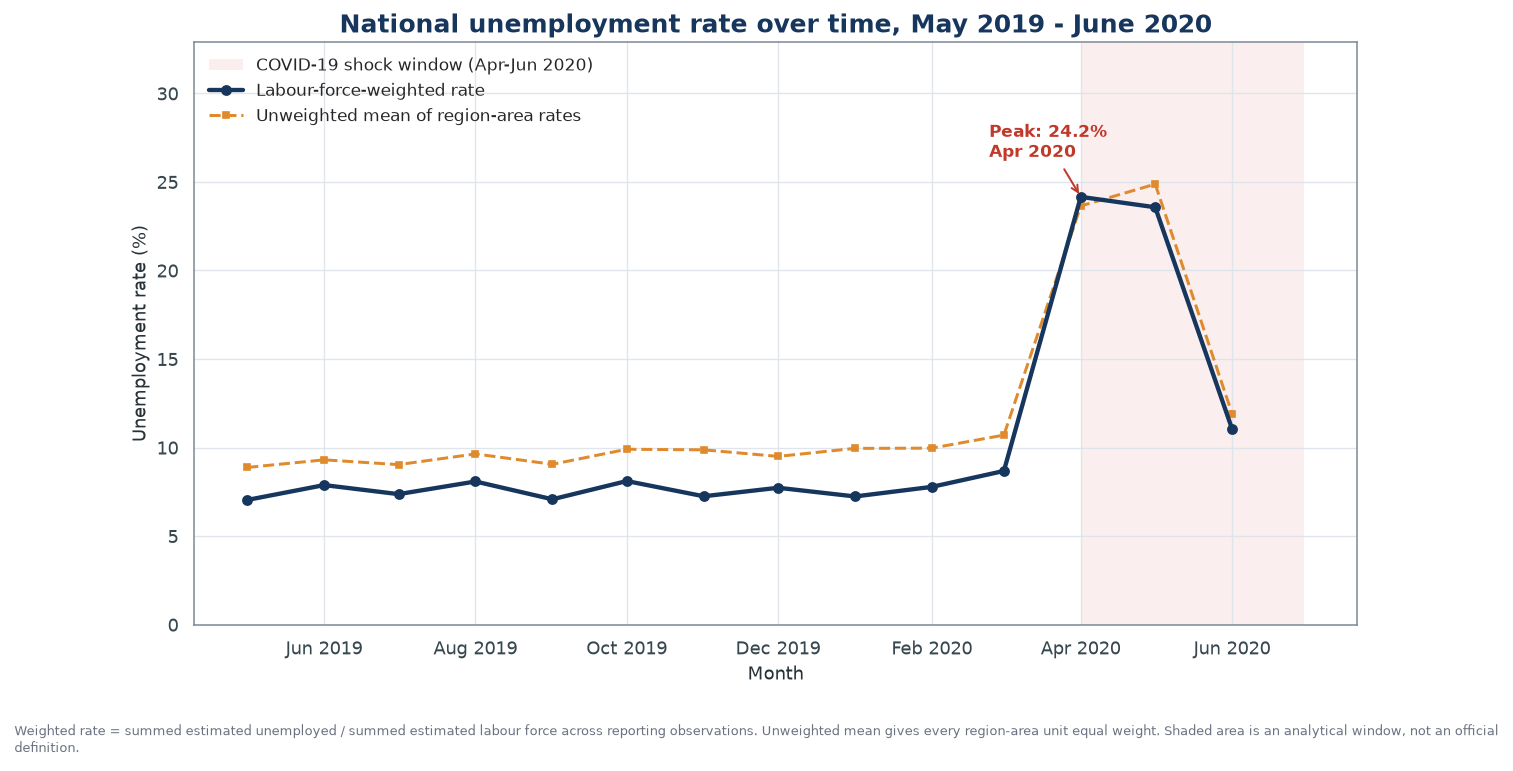

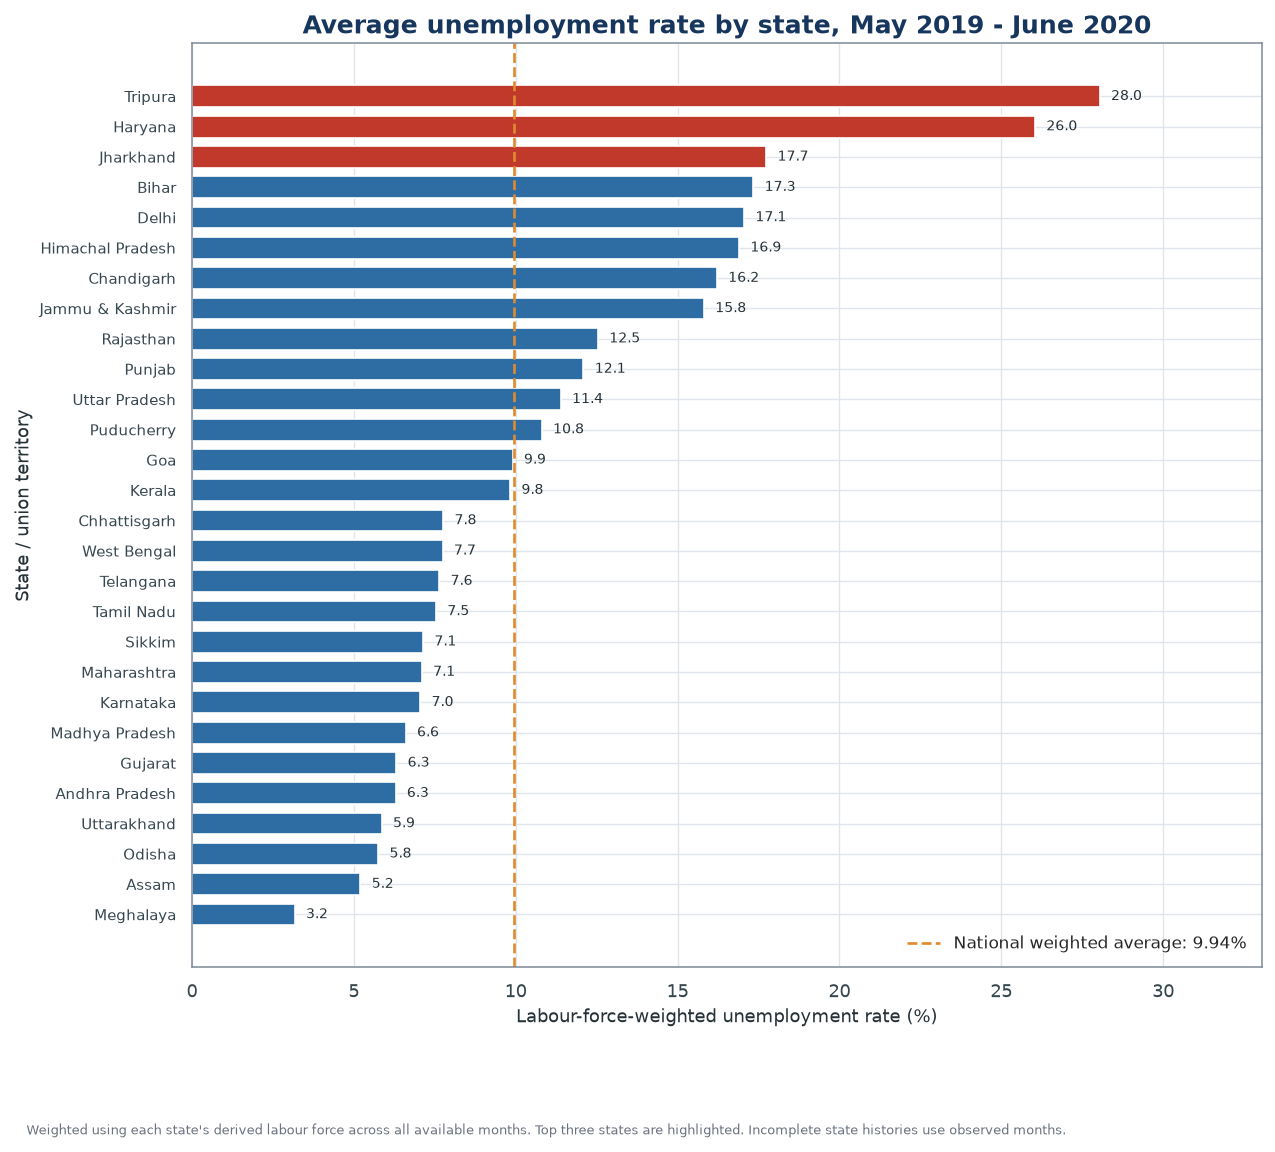

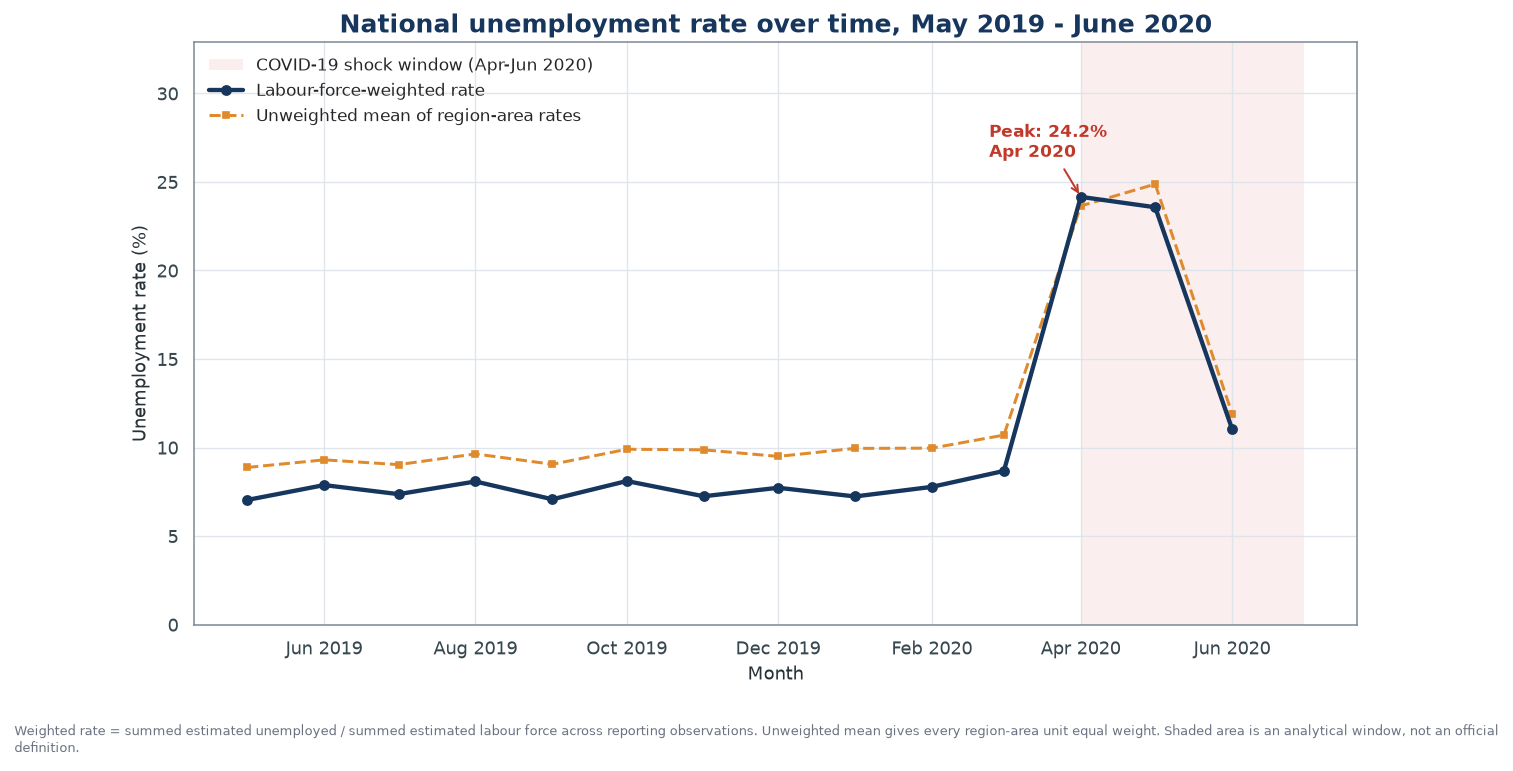

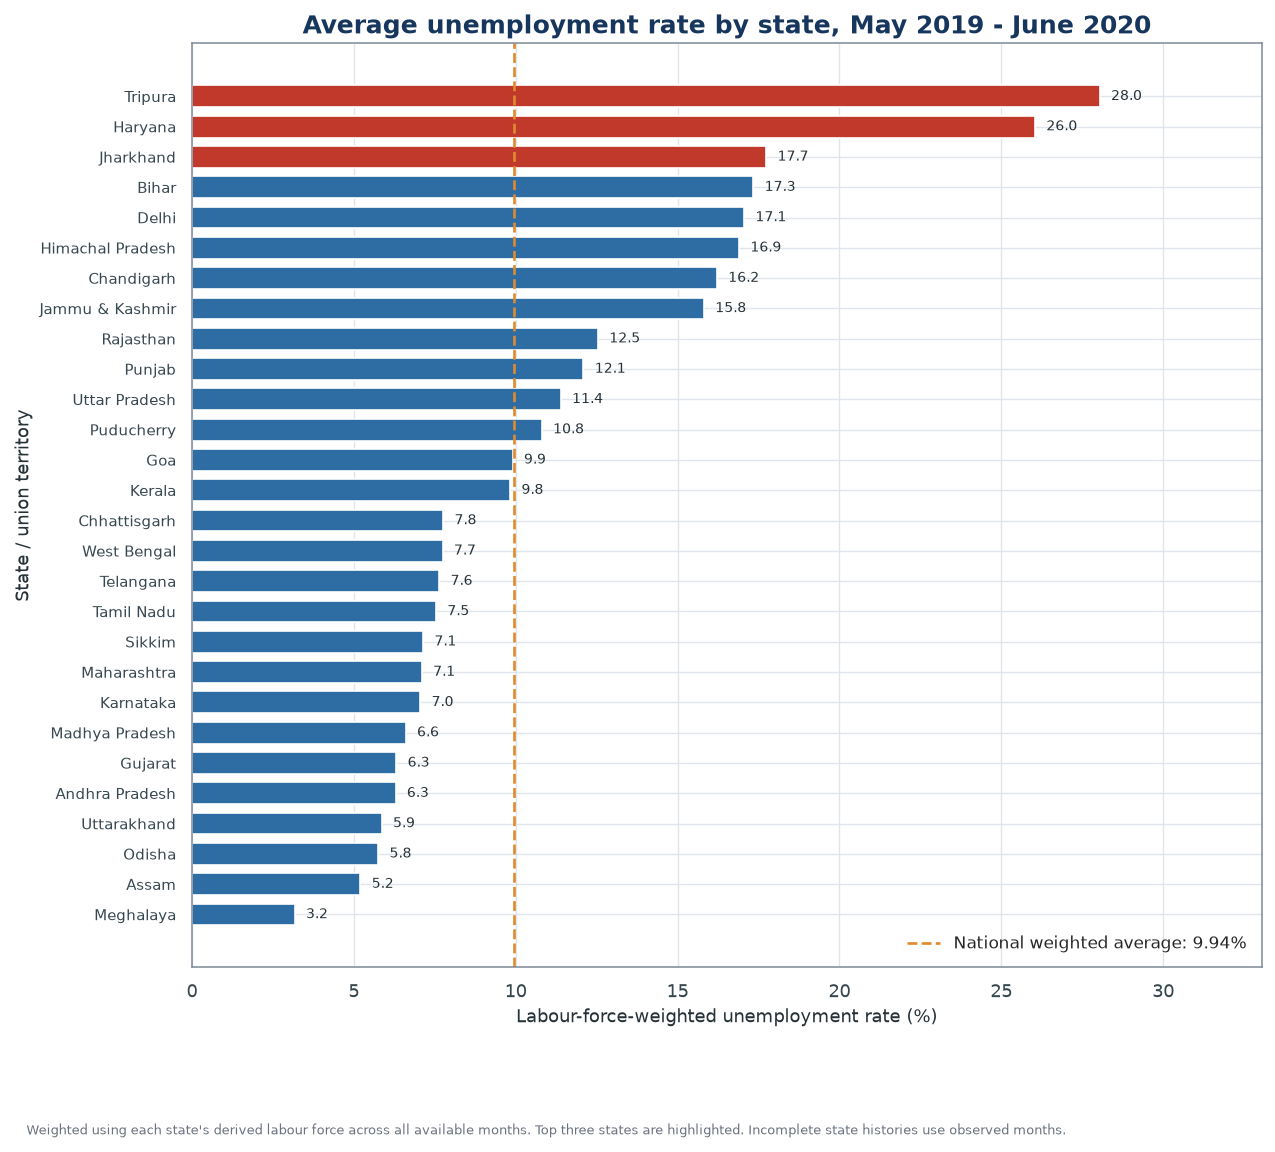

In [10]:
fig = charts.plot_overall_unemployment_trend(df1)
display(fig)

fig = charts.plot_state_unemployment_bar(df1)
display(fig)

**Reading the trend.** The weighted line is flat at roughly 7-8% from May 2019 to
February 2020, edges up in March, jumps to **24.16% in April 2020**, remains near
23.6% in May, and falls to 11.0% in June. The unweighted mean peaks at 24.88% in
May. The shaded Apr-Jun window is an analytical choice, not an official COVID
definition.

**Reading the state bars.** Tripura (28.04%) and
Haryana (26.04%) stand well above the national
weighted average of 9.94%. The distribution is not a
simple north-south story; state-specific labour markets matter.

### 5.2 Rural/urban, monthly dispersion and the shape of the distribution

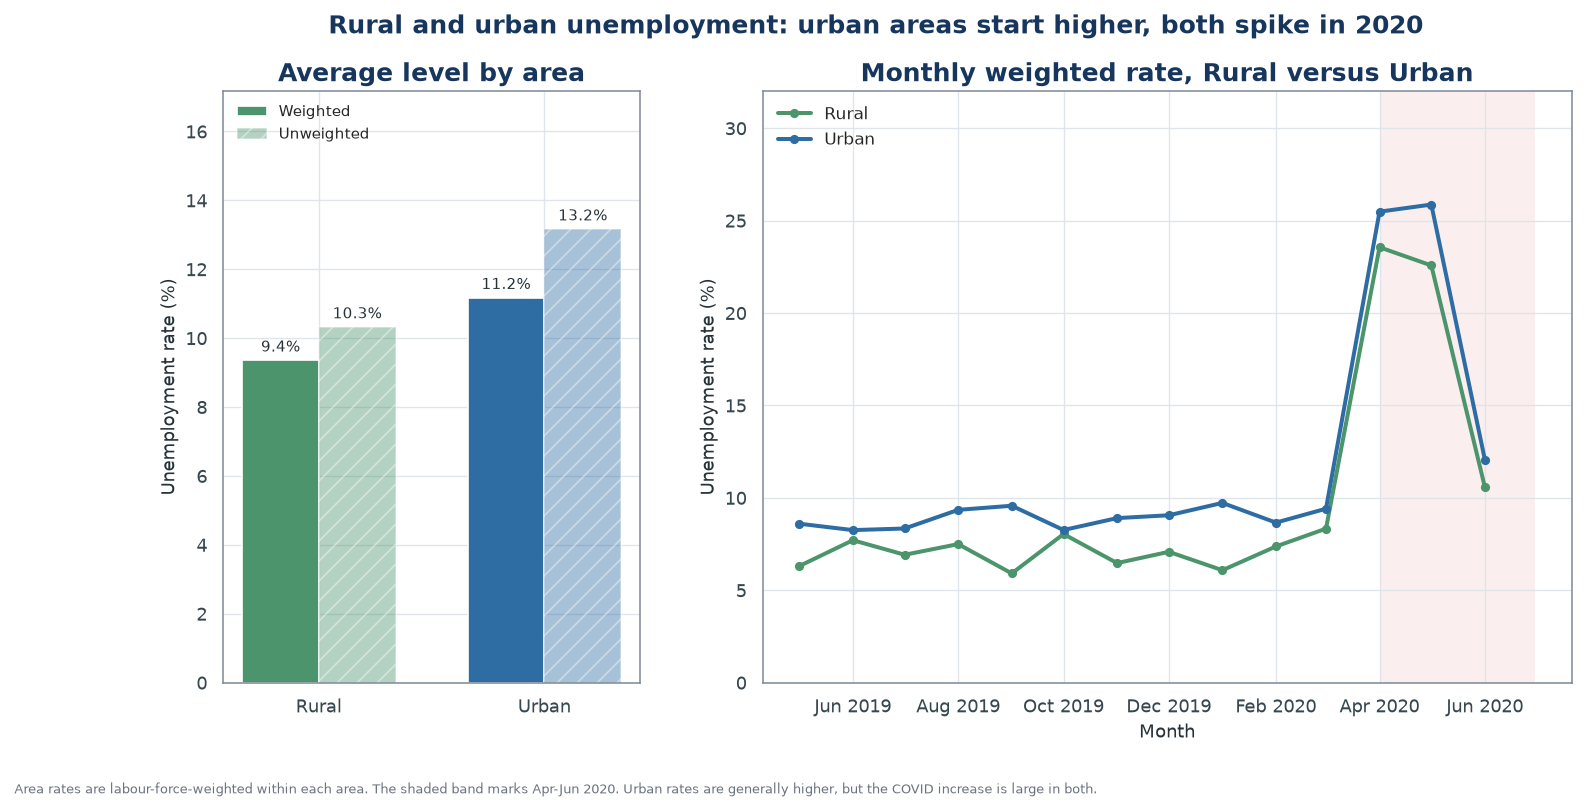

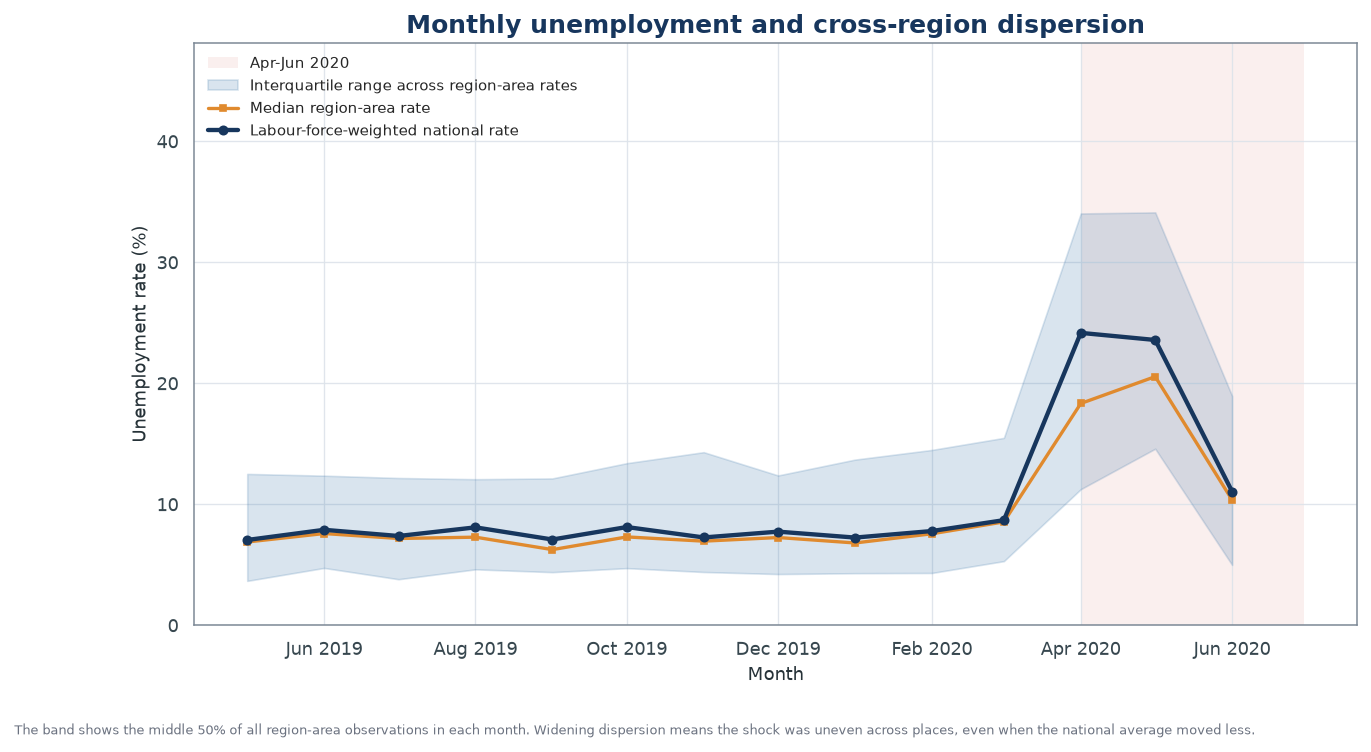

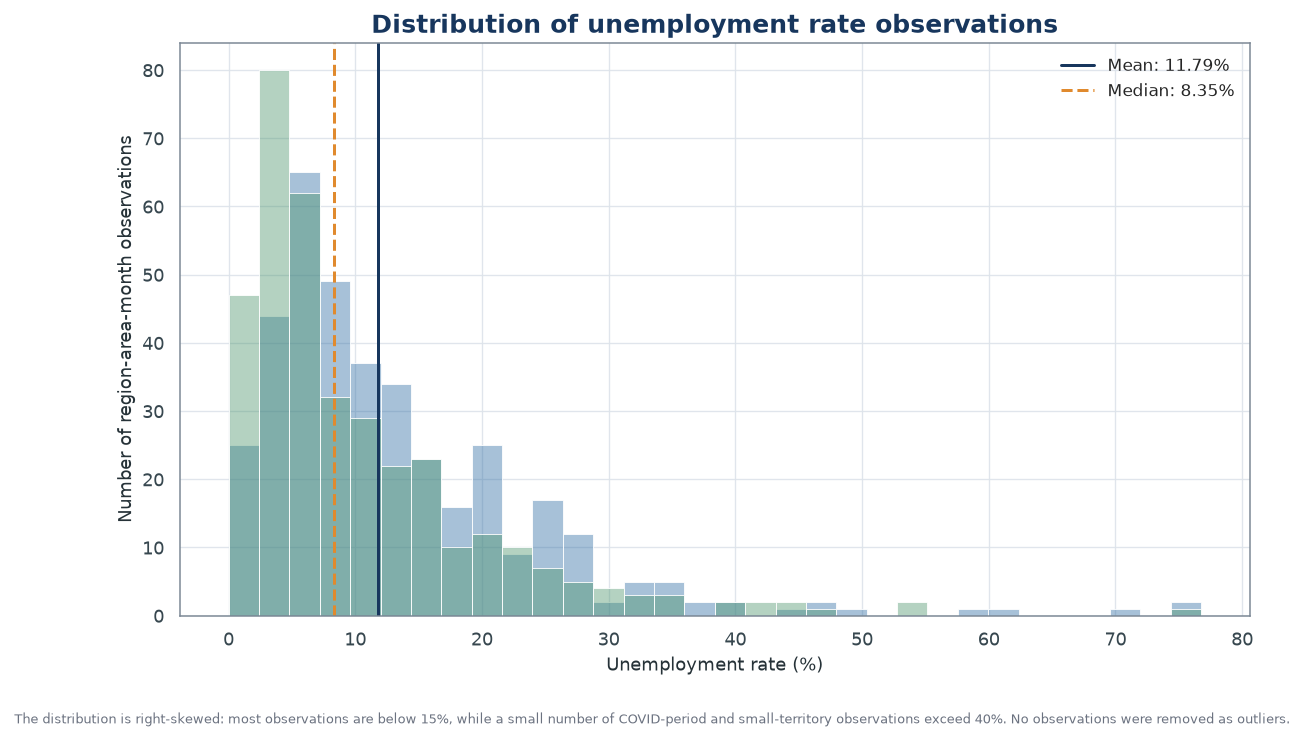

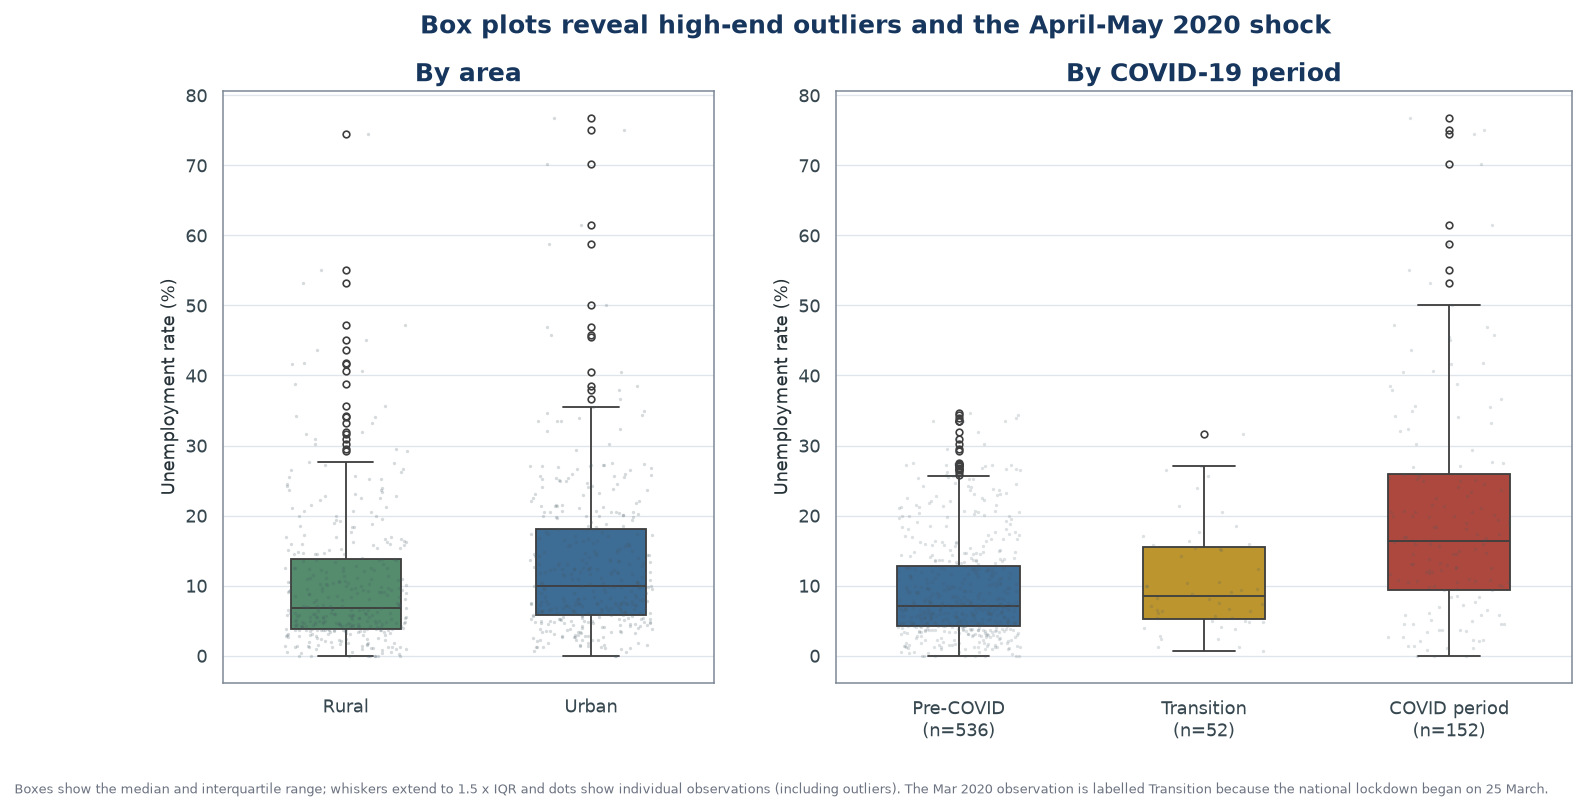

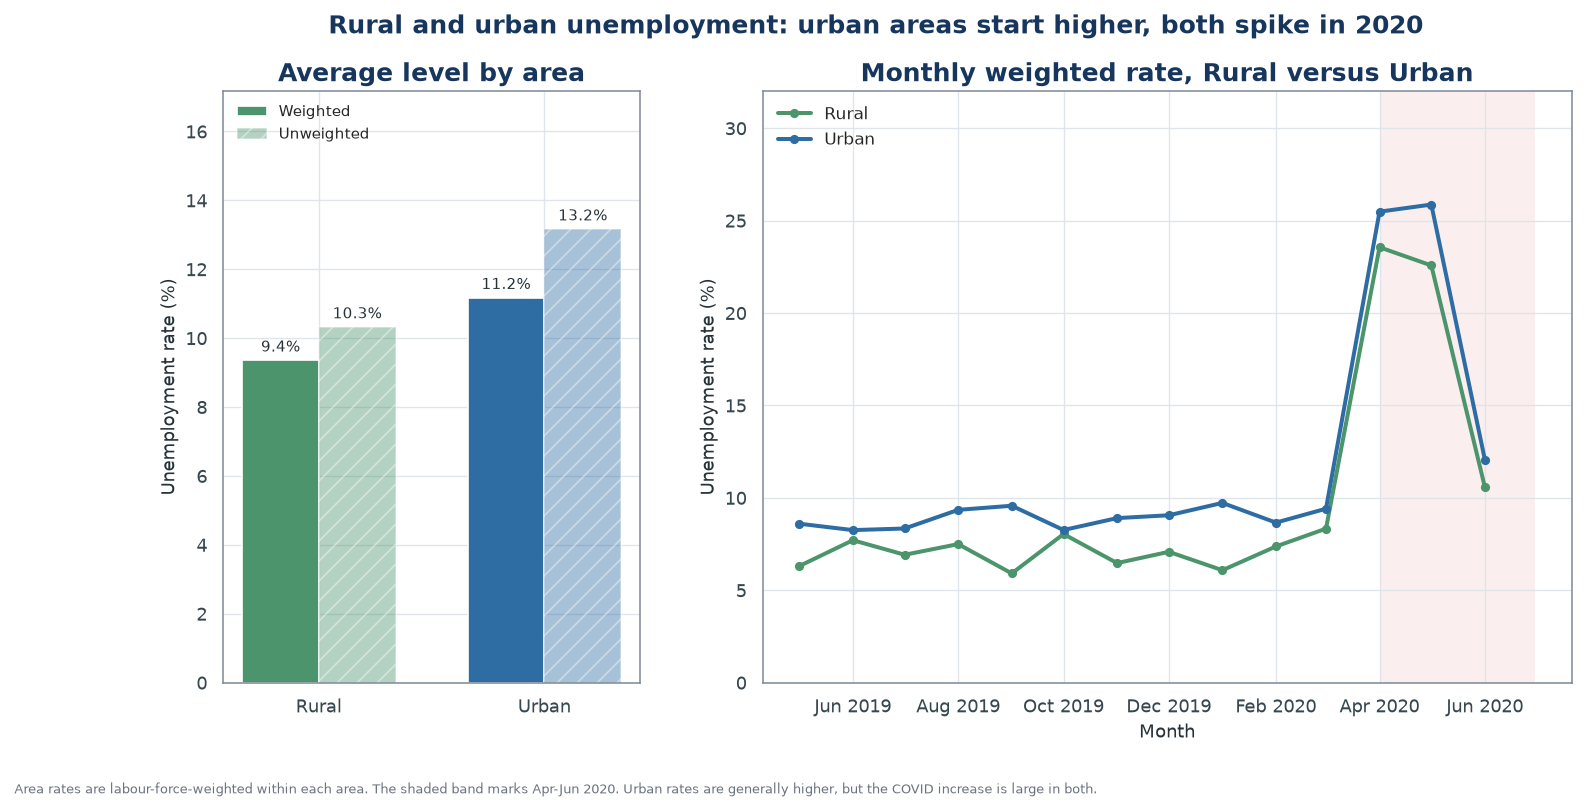

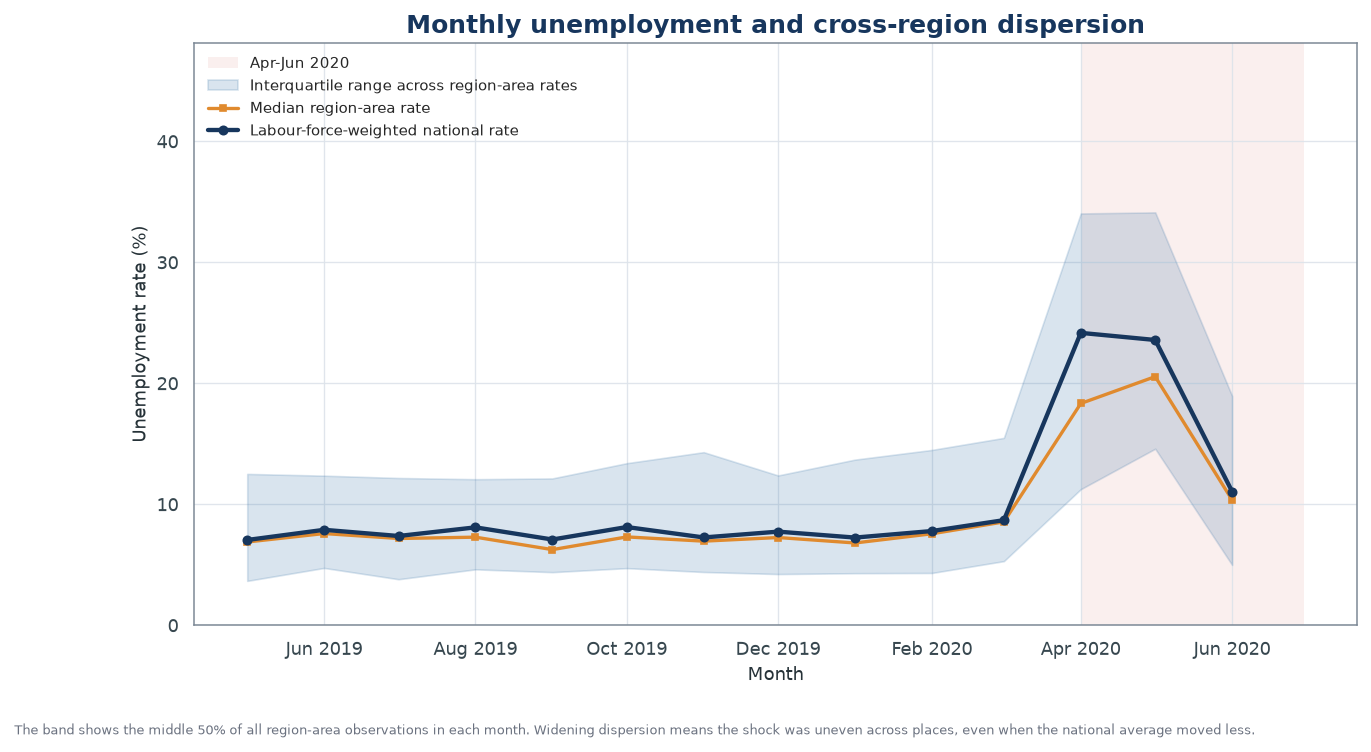

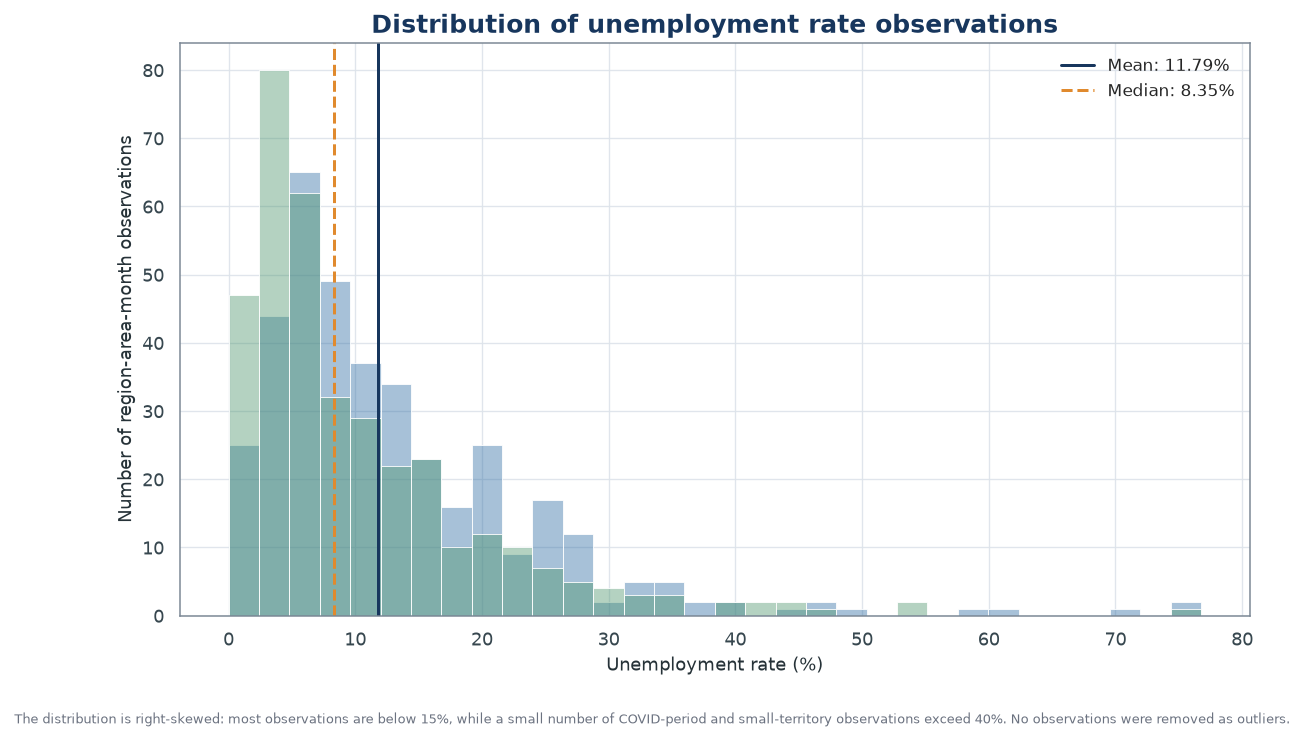

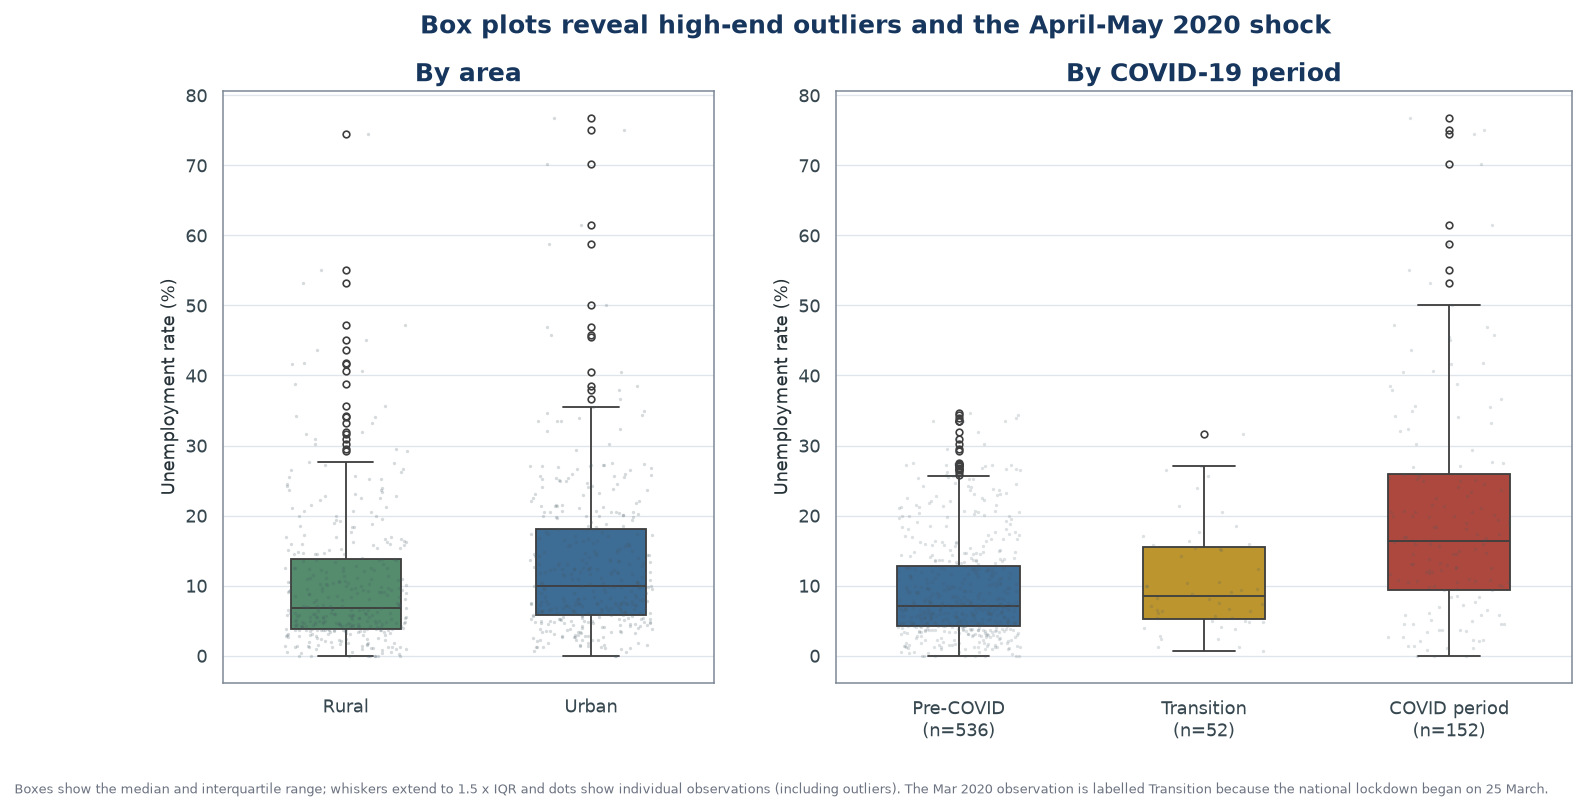

In [11]:
fig = charts.plot_rural_urban_comparison(df1)
display(fig)

fig = charts.plot_monthly_dispersion(df1)
display(fig)

fig = charts.plot_unemployment_distribution(df1)
display(fig)

fig = charts.plot_boxplot(df1)
display(fig)

**Area comparison.** Urban unemployment is higher before the shock, but both lines
jump in April. Urban peaks near 25.9% in May while rural peaks near 23.6% in April.
The rural line is lower on average but more volatile relative to its base.

**Dispersion.** The interquartile band widens sharply in April-May, showing that the
shock was highly uneven across places, not merely a uniform national shift.

**Distribution and outliers.** The histogram is right-skewed: most observations sit
below 15%, with a long tail above 40%. The IQR rule flags
**35 observations (4.7%)**
above 32.73%. They are retained because they are plausible
crisis observations, not data-entry errors; removing them would understate the shock.

### 5.3 Employment, participation and state-month timing

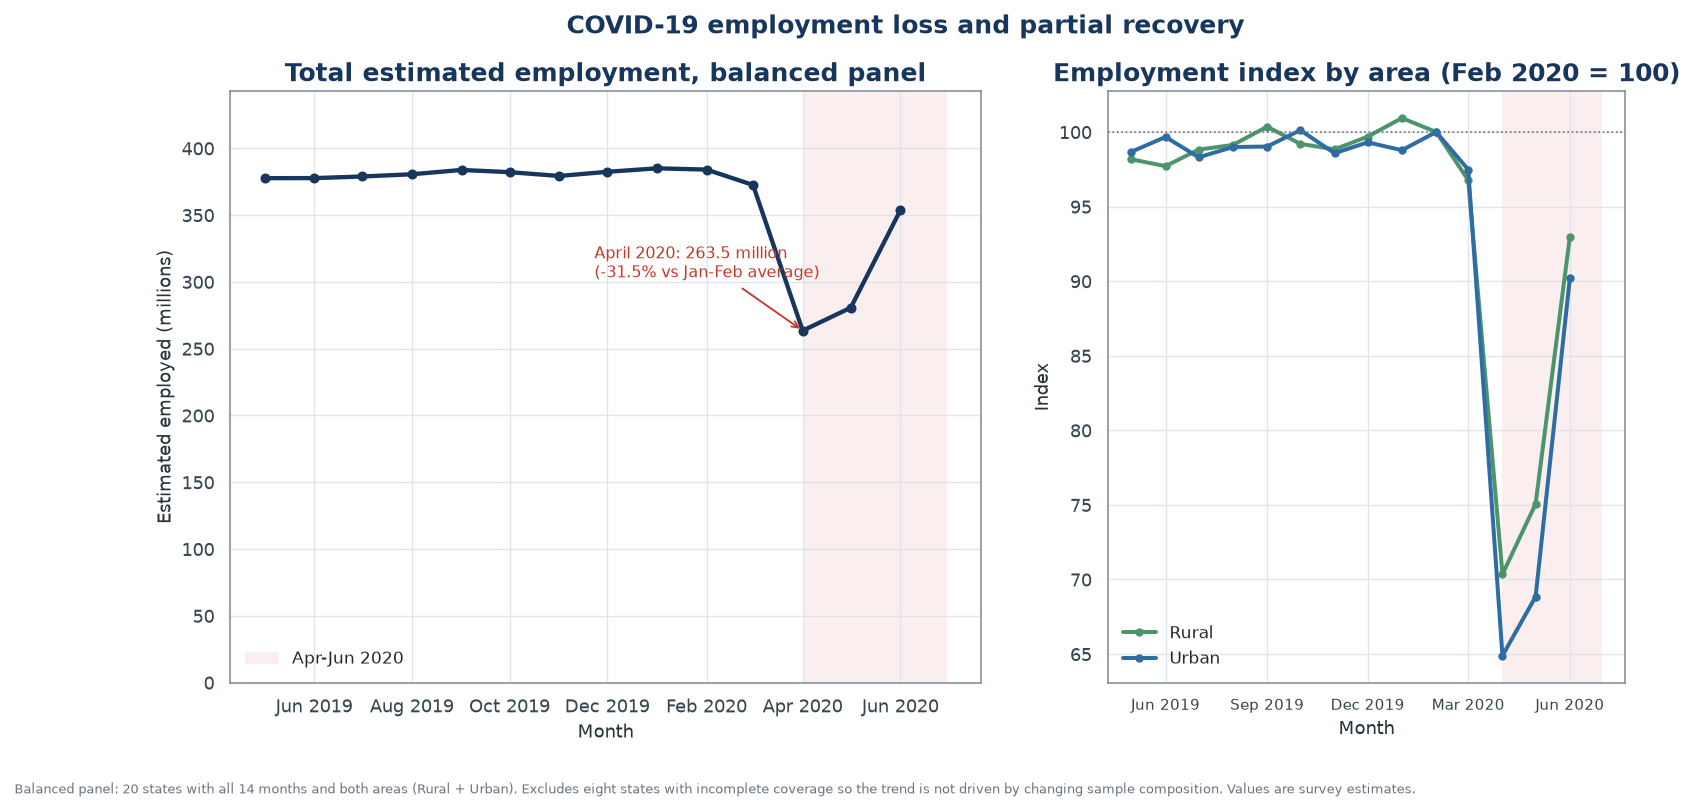

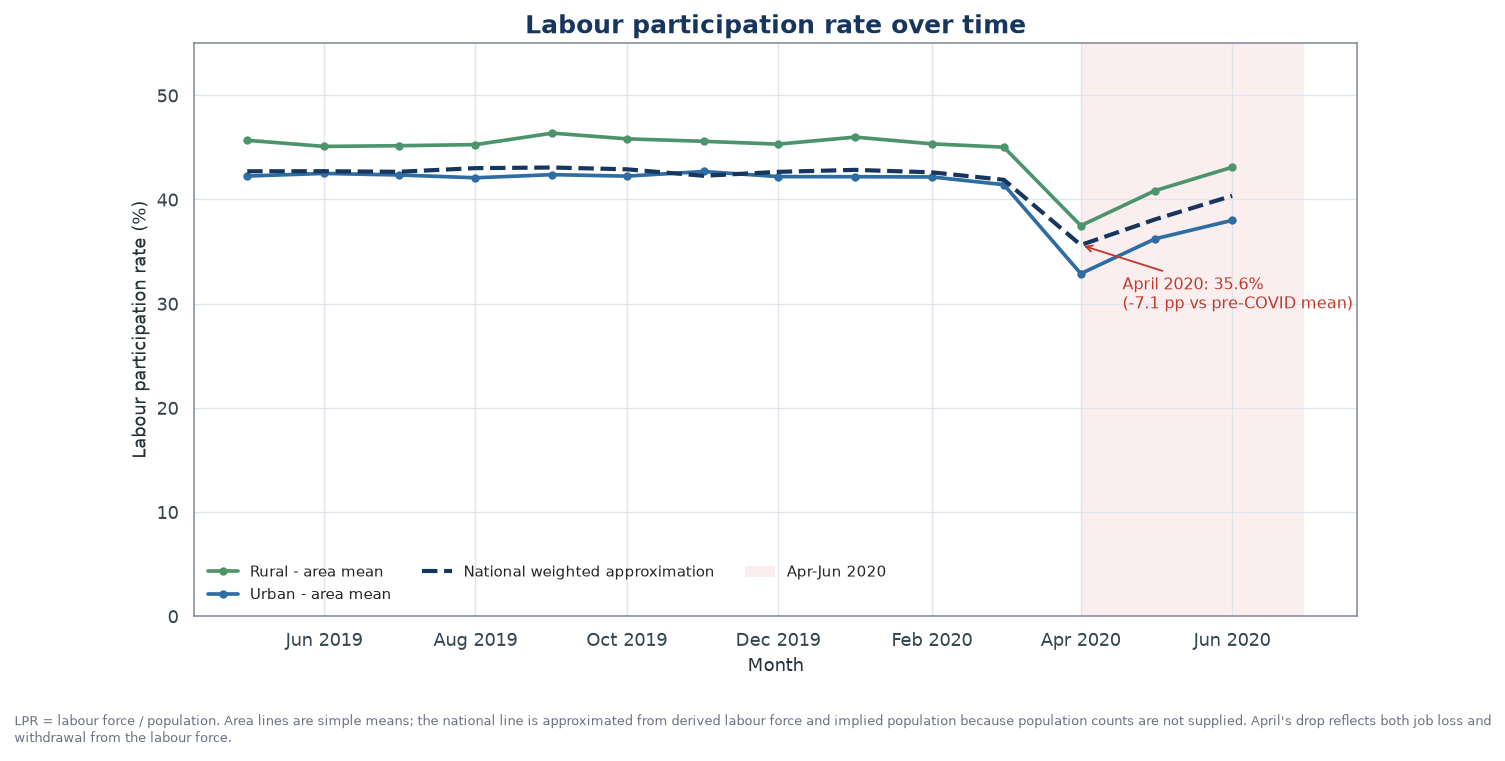

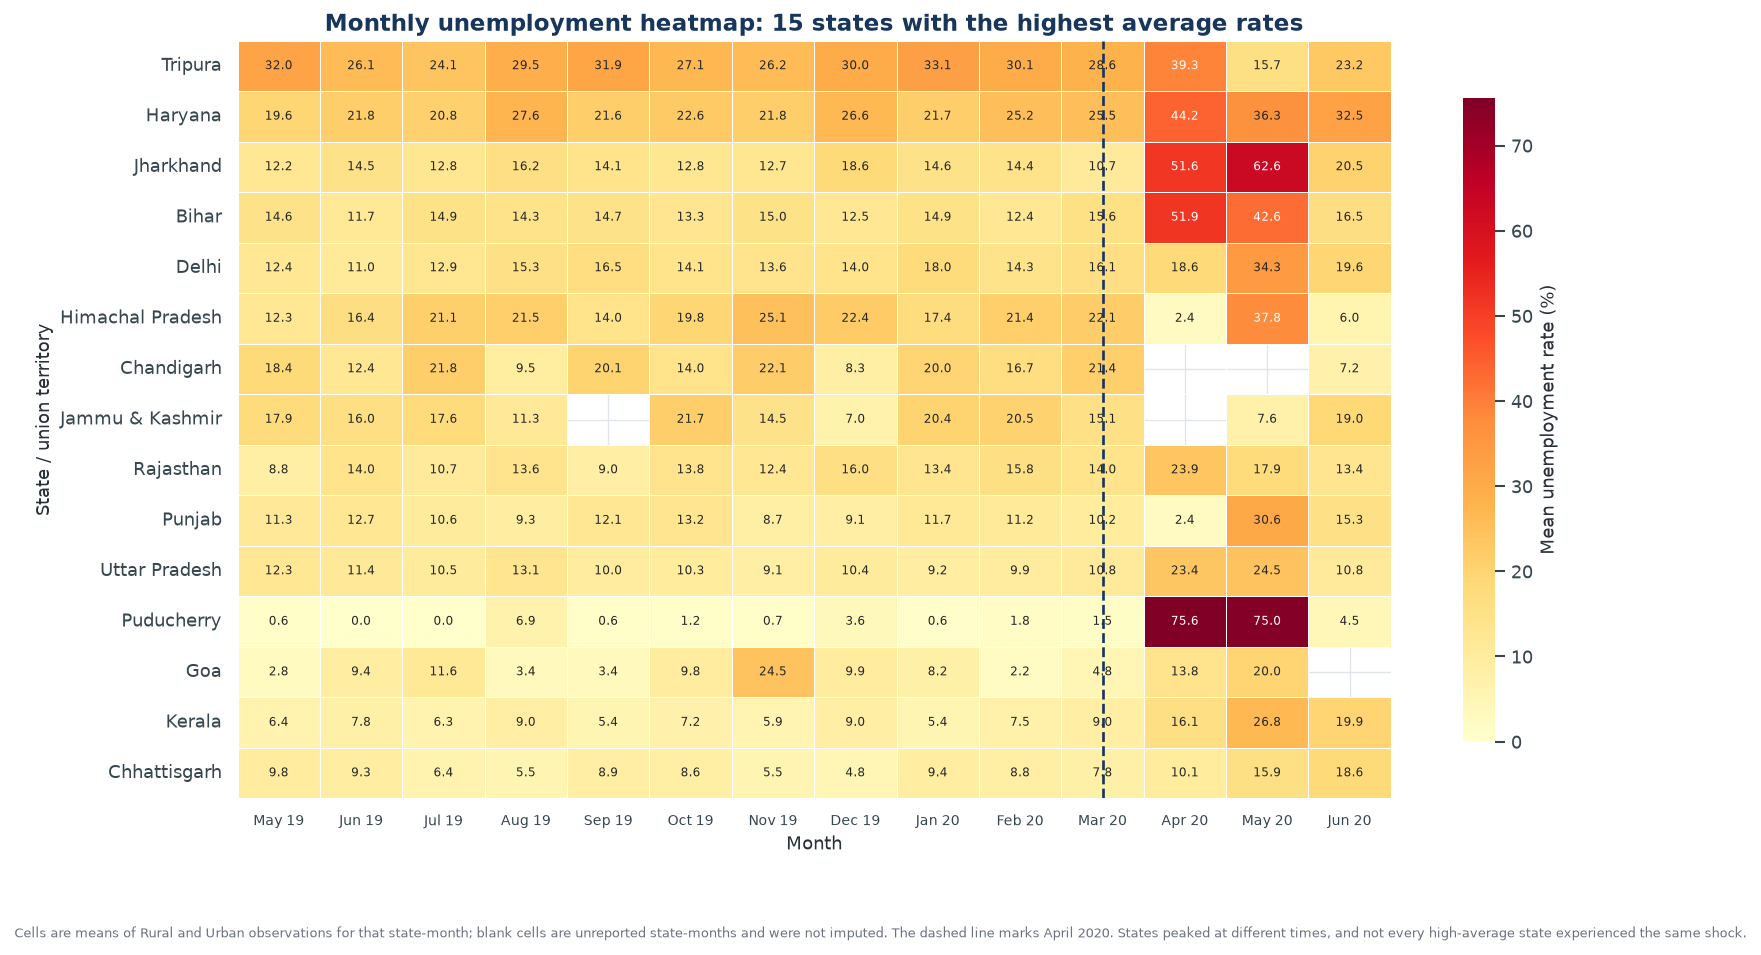

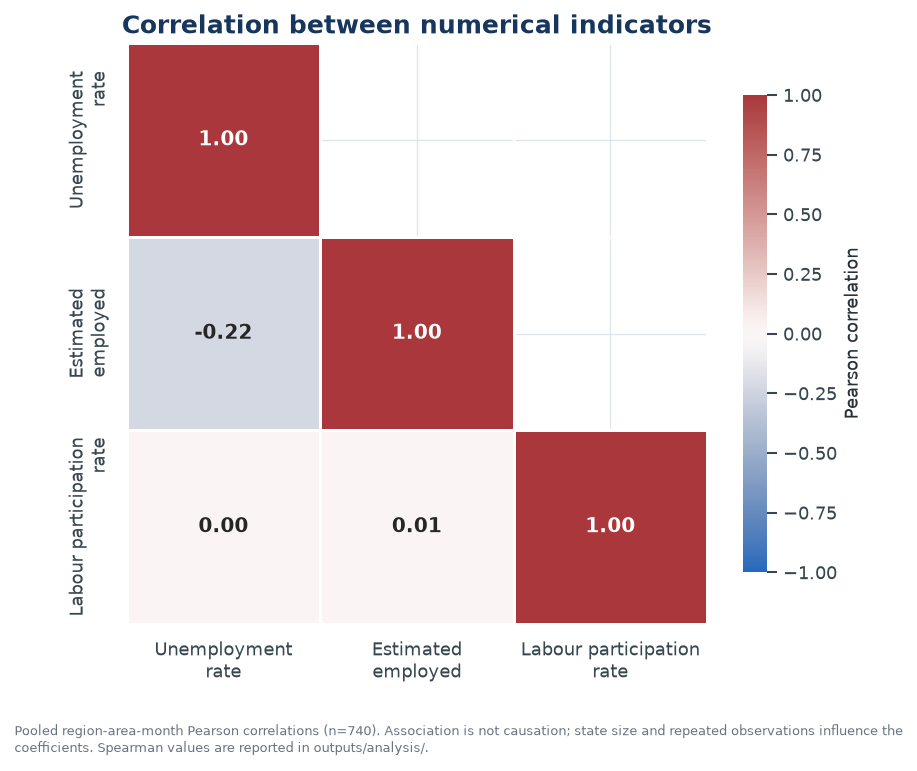

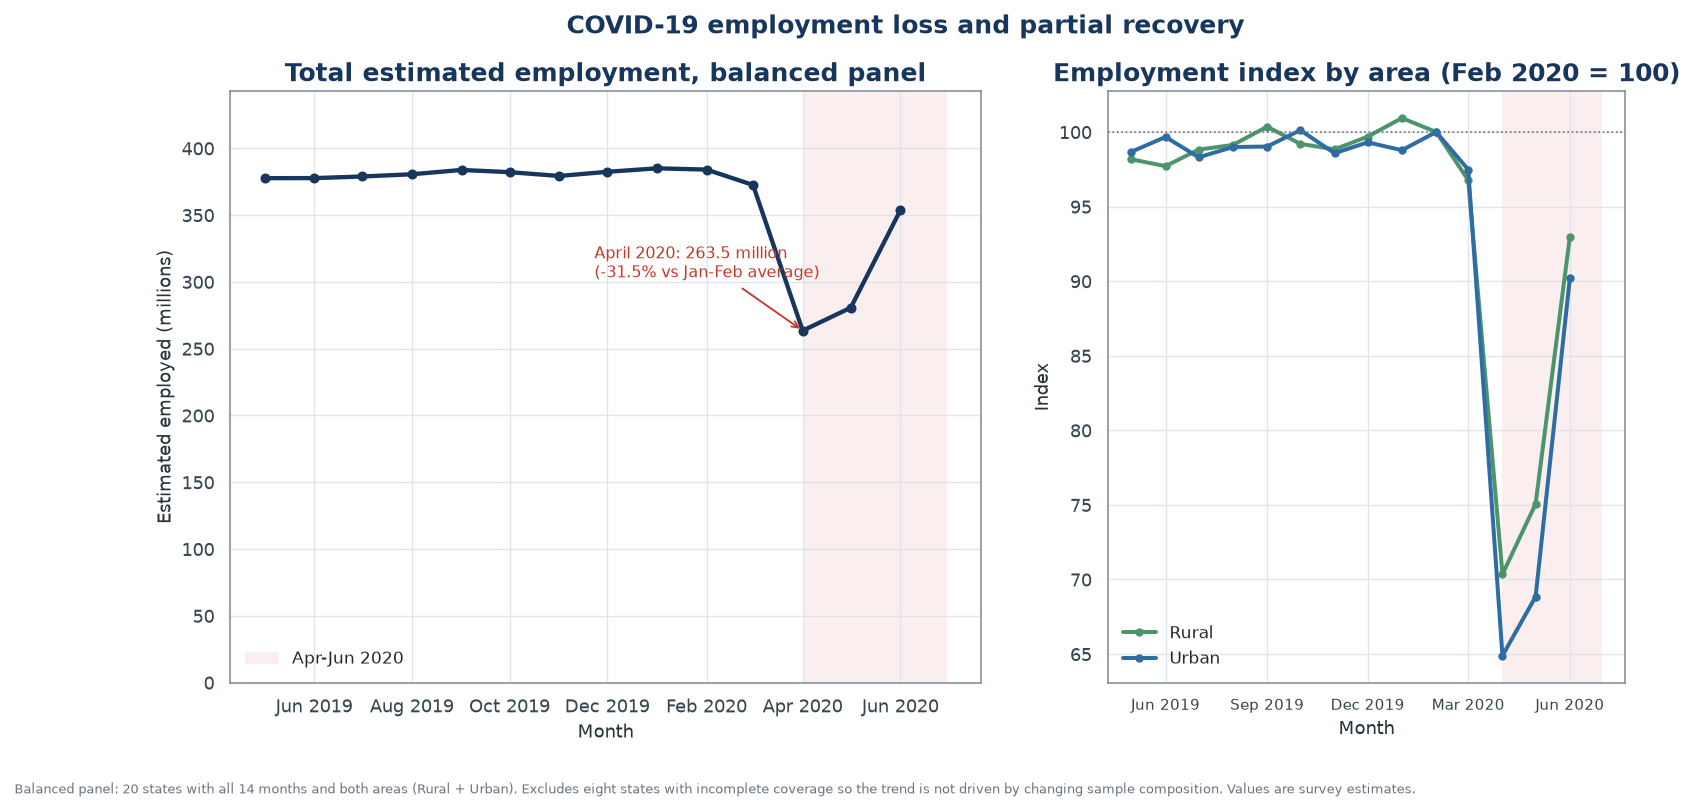

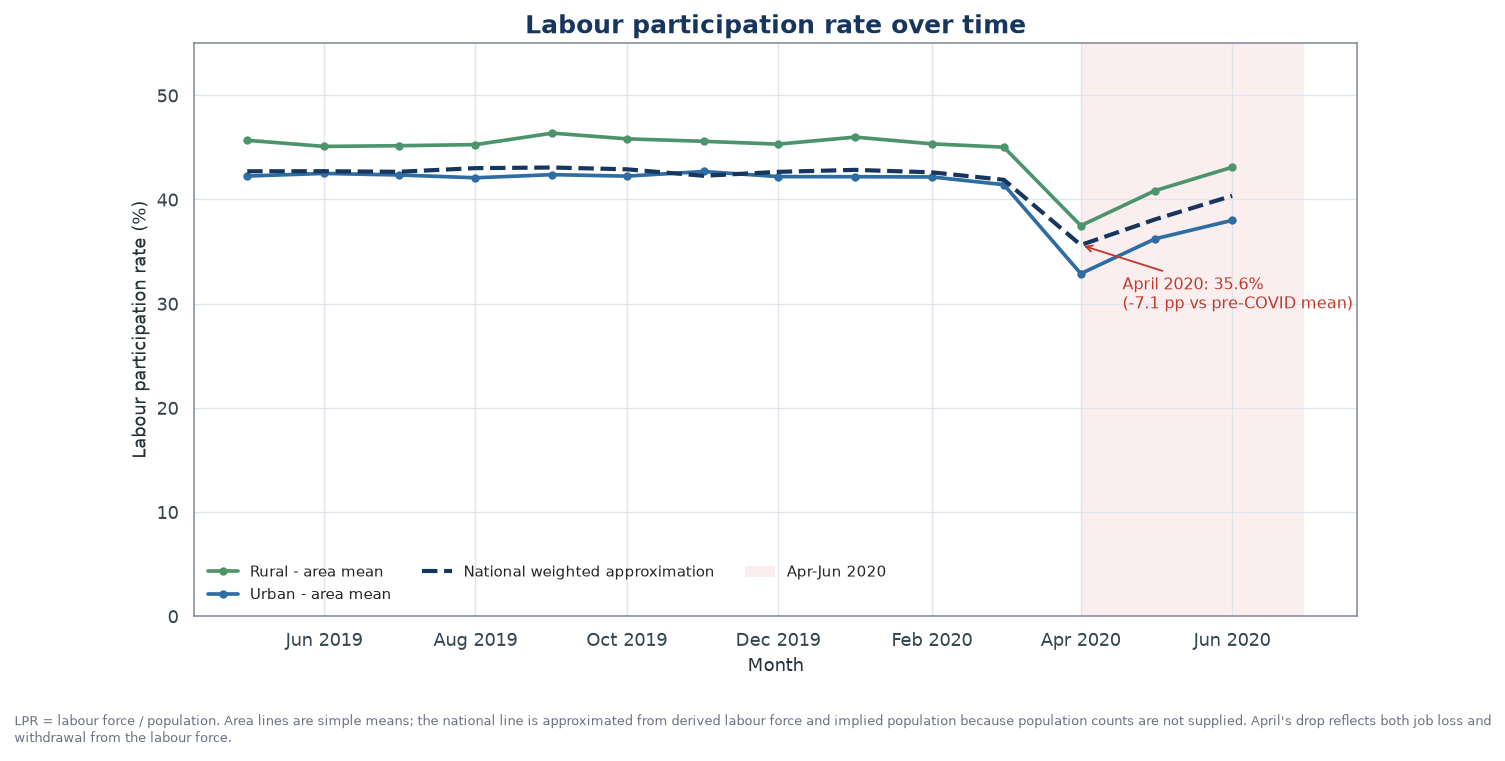

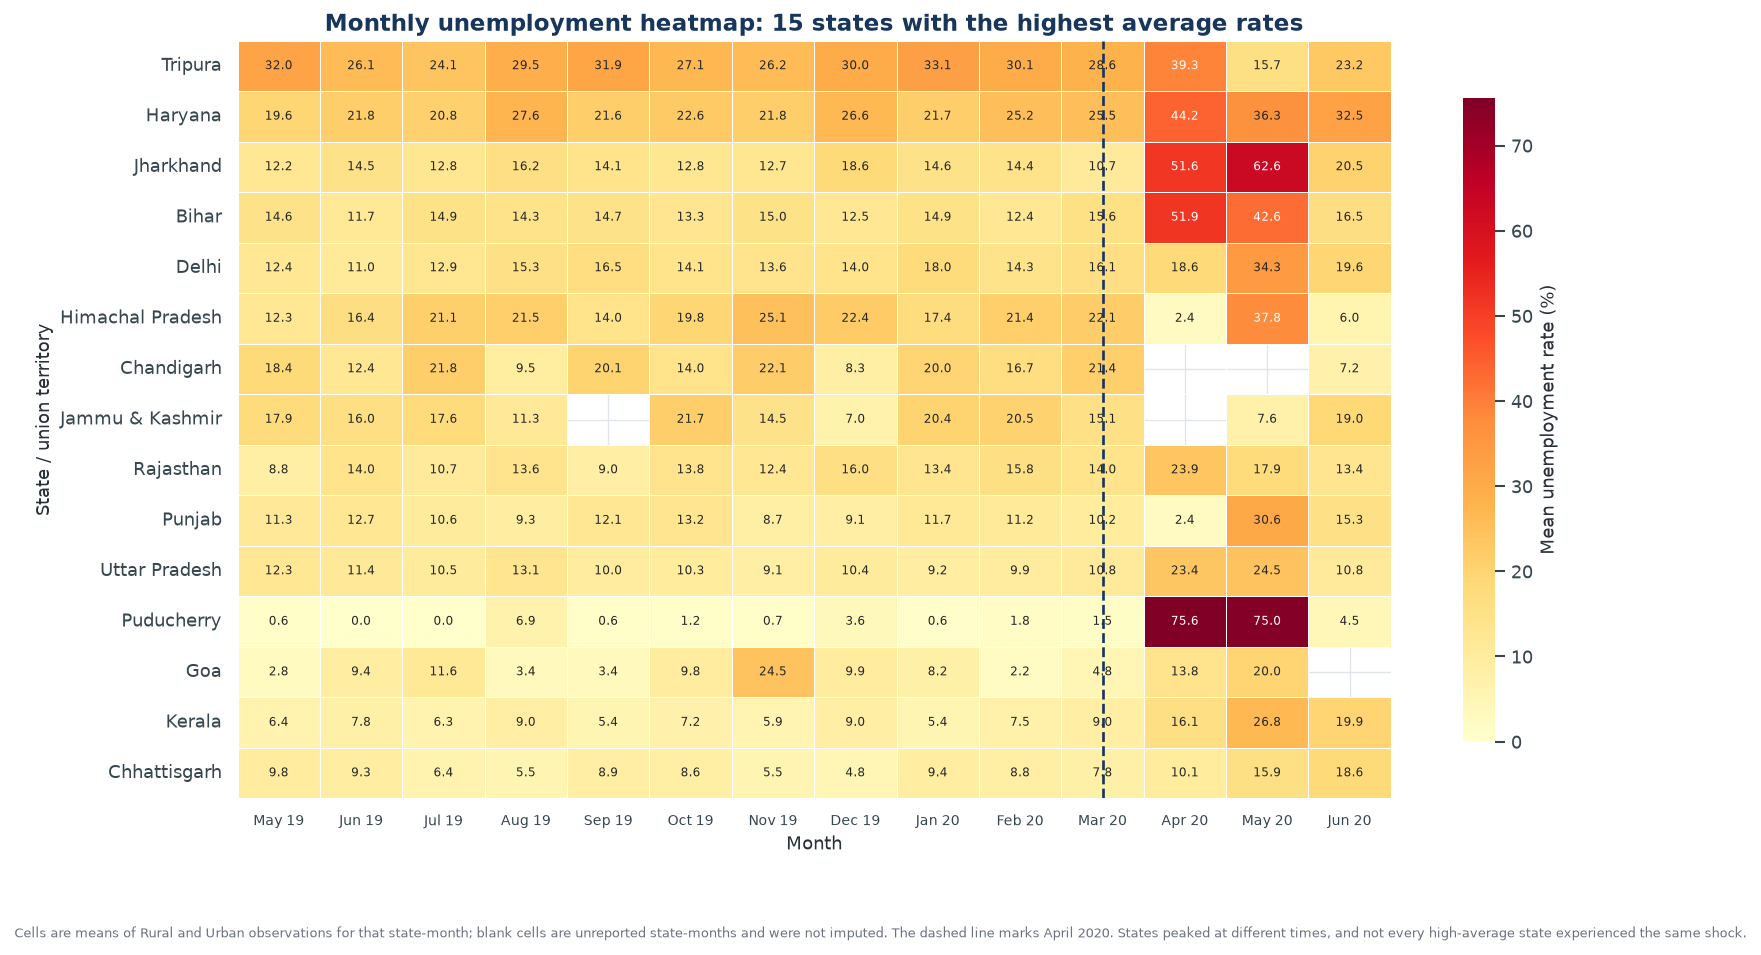

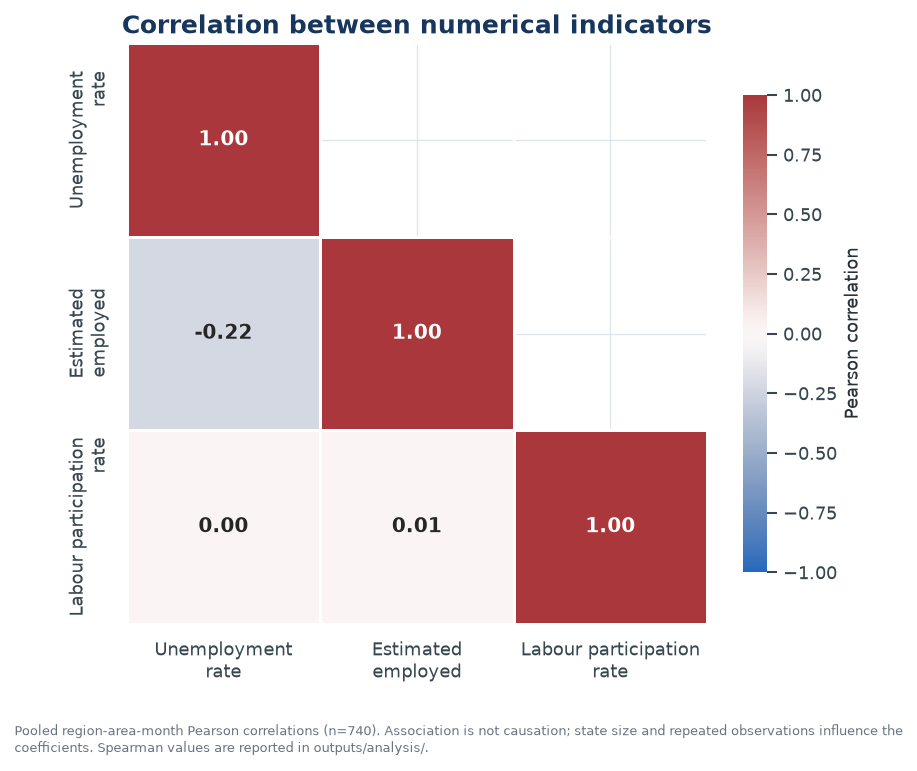

In [12]:
fig = charts.plot_employment_trend(df1)
display(fig)

fig = charts.plot_labour_participation(df1)
display(fig)

fig = charts.plot_state_month_heatmap(df1)
display(fig)

fig = charts.plot_correlation_heatmap(df1)
display(fig)

**Employment.** In the balanced panel of 20 states, April 2020 employment is
**263 million**, down
**121 million
(-31.5%)** from the January-February
average. June is still 8.0% below
baseline. Urban employment falls more sharply in April (-34.7%) than rural (-30.0%).

**Participation.** The estimated national LPR falls from about 42.7% before the
shock to 35.6% in April - a drop of roughly 7.1 pp. The decline is consistent with
both job loss and discouraged workers leaving the labour force; the dataset cannot
separate those mechanisms.

**Heatmap.** Some states peak in April (Puducherry, Haryana, Jharkhand), others in
May (Bihar, Tripura, Kerala). A state-level average masks timing. Blank cells are
genuinely unreported state-months.

## 6. COVID-19 impact analysis

### Period definitions

- **Immediate pre-COVID baseline:** January-February 2020.
- **Transition:** March 2020; the national lockdown began on 25 March, so this month
  straddles pre-shock and shock conditions.
- **COVID period:** April-June 2020.
- **Peak window:** April-May 2020.

These are analytical windows, not official definitions. Changes are measured in
percentage points (pp) and relative percentages where useful. They are not causal
effects.

In [13]:
def period_subset(frame, start, end):
    return frame[frame["date"].between(pd.Timestamp(start), pd.Timestamp(end))]

period_defs = [
    ("Pre-COVID full (May 2019-Feb 2020)", "2019-05-01", "2020-02-29"),
    ("Immediate baseline (Jan-Feb 2020)", "2020-01-01", "2020-02-29"),
    ("Transition (Mar 2020)", "2020-03-01", "2020-03-31"),
    ("COVID period (Apr-Jun 2020)", "2020-04-01", "2020-06-30"),
    ("Peak (Apr-May 2020)", "2020-04-01", "2020-05-31"),
    ("June 2020", "2020-06-01", "2020-06-30"),
]
period_rows = []
for label, start, end in period_defs:
    group = period_subset(df1, start, end)
    period_rows.append(
        {
            "period": label,
            "n_obs": len(group),
            "n_regions": group["region"].nunique(),
            "weighted_rate": utils.weighted_rate(group),
            "unweighted_rate": group["unemployment_rate"].mean(),
            "average_lpr": group["labour_participation_rate"].mean(),
            "total_employed_reported": group["estimated_employed"].sum(),
        }
    )
period_table = pd.DataFrame(period_rows)
display(period_table.round(2))

baseline = period_subset(df1, "2020-01-01", "2020-02-29")
crisis = period_subset(df1, "2020-04-01", "2020-06-30")
baseline_rate = utils.weighted_rate(baseline)
crisis_rate = utils.weighted_rate(crisis)
print(f"Baseline weighted rate: {baseline_rate:.2f}%")
print(f"COVID weighted rate: {crisis_rate:.2f}%")
print(f"Absolute change: {crisis_rate - baseline_rate:+.2f} pp")
print(f"Relative change: {(crisis_rate / baseline_rate - 1) * 100:+.1f}%")

,period,n_obs,n_regions,weighted_rate,unweighted_rate,average_lpr,total_employed_reported
0,Pre-COVID full (May 2019-Feb 2020),536,28,7.55,9.51,43.89,"4,001,790,938.00"
1,Immediate baseline (Jan-Feb 2020),106,27,7.51,9.96,43.89,"809,911,057.00"
2,Transition (Mar 2020),52,28,8.67,10.70,43.08,"390,862,219.00"
3,COVID period (Apr-Jun 2020),152,28,19.28,20.19,38.05,"938,647,262.00"
4,Peak (Apr-May 2020),102,27,23.85,24.26,36.82,"569,296,829.00"
5,June 2020,50,27,11.04,11.90,40.55,"369,350,433.00"


Baseline weighted rate: 7.51%
COVID weighted rate: 19.28%
Absolute change: +11.77 pp
Relative change: +156.8%


### Headline change

The weighted national rate rises from **7.51%**
in January-February 2020 to **19.28%** in
April-June 2020: **+11.77 pp**, or
**+156.8%**.

The April-May peak is **23.85%**, an increase of
**+16.34 pp** over baseline. March (during the first
lockdown days) is **8.67%**, while June is already
down to **11.04%**. This is a sharp spike and partial early
rebound, not evidence of a gradual trend that began earlier.

In [14]:
area_change_rows = []
for label, pre, during in [
    ("All", baseline, crisis),
    ("Rural", baseline[baseline["area"] == "Rural"], crisis[crisis["area"] == "Rural"]),
    ("Urban", baseline[baseline["area"] == "Urban"], crisis[crisis["area"] == "Urban"]),
]:
    pre_rate = utils.weighted_rate(pre)
    during_rate = utils.weighted_rate(during)
    area_change_rows.append(
        {
            "group": label,
            "baseline": pre_rate,
            "covid": during_rate,
            "change_pp": during_rate - pre_rate,
            "change_pct": (during_rate / pre_rate - 1) * 100,
            "baseline_lpr": pre["labour_participation_rate"].mean(),
            "covid_lpr": during["labour_participation_rate"].mean(),
        }
    )
display(pd.DataFrame(area_change_rows).round(2))

state_rows = []
for region in sorted(df1["region"].unique()):
    pre = baseline[baseline["region"] == region]
    during = crisis[crisis["region"] == region]
    if pre.empty or during.empty:
        continue
    pre_rate = utils.weighted_rate(pre)
    during_rate = utils.weighted_rate(during)
    state_rows.append(
        {
            "region": region,
            "baseline": pre_rate,
            "covid": during_rate,
            "change_pp": during_rate - pre_rate,
            "baseline_obs": len(pre),
            "covid_obs": len(during),
        }
    )
state_change = pd.DataFrame(state_rows).sort_values("change_pp", ascending=False)
display(state_change.head(12).round(2))
display(state_change.tail(5).round(2))

,group,baseline,covid,change_pp,change_pct,baseline_lpr,covid_lpr
0,All,7.51,19.28,11.77,156.80,43.89,38.05
1,Rural,6.72,18.61,11.89,176.93,45.67,40.48
2,Urban,9.19,20.77,11.58,126.06,42.17,35.67


,region,baseline,covid,change_pp,baseline_obs,covid_obs
18,Puducherry,1.20,57.92,56.73,4,4
11,Jharkhand,11.24,41.91,30.67,4,6
21,Tamil Nadu,1.83,31.62,29.79,4,6
2,Bihar,10.45,37.56,27.11,4,6
12,Karnataka,3.22,19.42,16.19,4,6
13,Kerala,6.46,21.84,15.38,4,6
8,Haryana,23.08,37.53,14.45,4,6
22,Telangana,6.88,19.78,12.91,4,6
14,Madhya Pradesh,4.34,15.94,11.59,4,6
15,Maharashtra,4.82,15.23,10.41,4,6


,region,baseline,covid,change_pp,baseline_obs,covid_obs
4,Chhattisgarh,9.00,9.85,0.85,4,6
9,Himachal Pradesh,16.84,12.93,-3.90,4,6
23,Tripura,30.54,25.97,-4.57,4,6
10,Jammu & Kashmir,20.94,10.67,-10.27,4,3
3,Chandigarh,18.41,7.22,-11.19,2,1


### Area pattern

- **Rural:** 6.72% -> 18.61%
  (+11.89 pp, +176.9%).
- **Urban:** 9.19% -> 20.77%
  (+11.58 pp, +126.1%).

The absolute increases are nearly identical, but the rural increase is larger in
relative terms because rural unemployment started from a lower base. Urban
unemployment remains higher in absolute terms. Both rural and urban LPR fell
(rural -5.18 pp; urban -6.50 pp).

### Regional pattern

The largest absolute increases are **Puducherry +56.7 pp**,
**Jharkhand +30.7 pp**, **Tamil Nadu +29.8 pp**,
**Bihar +27.1 pp** and **Karnataka +16.2 pp**.
Puducherry's change starts from an unusually low 1.20% baseline
and is based on only four baseline observations; it is a warning about small-area
volatility, not a typical state experience. Among larger states, Jharkhand, Tamil Nadu
and Bihar stand out.

Some high-average states did **not** rise: Tripura fell from 30.54% to 25.97%,
Jammu & Kashmir from 20.94% to 10.67% (with incomplete April data), and Himachal
Pradesh from 16.84% to 12.93%. A high level and a large shock are different policy
problems.

In [15]:
months = df1["month"].nunique()
areas = df1["area"].nunique()
counts = df1.groupby("region").size()
complete_states = counts[counts == months * areas].index.tolist()
panel = df1[df1["region"].isin(complete_states)]

panel_monthly = (
    panel.groupby(["month_start", "area"])["estimated_employed"].sum().unstack("area")
)
panel_monthly["total"] = panel_monthly.sum(axis=1)
baseline_months = panel_monthly.loc[
    panel_monthly.index.isin([pd.Timestamp("2020-01-01"), pd.Timestamp("2020-02-01")])
]
base_total = baseline_months["total"].mean()
base_rural = baseline_months["Rural"].mean()
base_urban = baseline_months["Urban"].mean()
employment_changes = pd.DataFrame(
    {
        "total_millions": panel_monthly["total"] / 1e6,
        "total_vs_baseline_pct": (panel_monthly["total"] / base_total - 1) * 100,
        "rural_vs_baseline_pct": (panel_monthly["Rural"] / base_rural - 1) * 100,
        "urban_vs_baseline_pct": (panel_monthly["Urban"] / base_urban - 1) * 100,
    }
)
print("Balanced panel states:", len(complete_states))
display(employment_changes.round(2))

Balanced panel states: 20


,total_millions,total_vs_baseline_pct,rural_vs_baseline_pct,urban_vs_baseline_pct
month_start,,,,
2019-05-01,377.63,-1.79,-2.29,-0.72
2019-06-01,377.66,-1.78,-2.74,0.28
2019-07-01,378.88,-1.47,-1.64,-1.09
2019-08-01,380.54,-1.03,-1.33,-0.40
2019-09-01,383.77,-0.19,-0.11,-0.37
2019-10-01,382.12,-0.62,-1.25,0.74
2019-11-01,379.26,-1.37,-1.62,-0.82
2019-12-01,382.39,-0.55,-0.77,-0.08
2020-01-01,384.98,0.12,0.46,-0.61


### Employment loss

The balanced panel of 20
states avoids changing sample composition. April 2020 total employment is
**263.5 million**, a fall of
**121.0 million
(-31.5%)** from the January-February
average. May is -27.0% below baseline and
June is -8.0% below.

Employment loss is concentrated in April. By June, jobs are recovering but are still
materially below the pre-shock level. This is consistent with the unemployment rate
falling faster than employment because some people left the labour force.

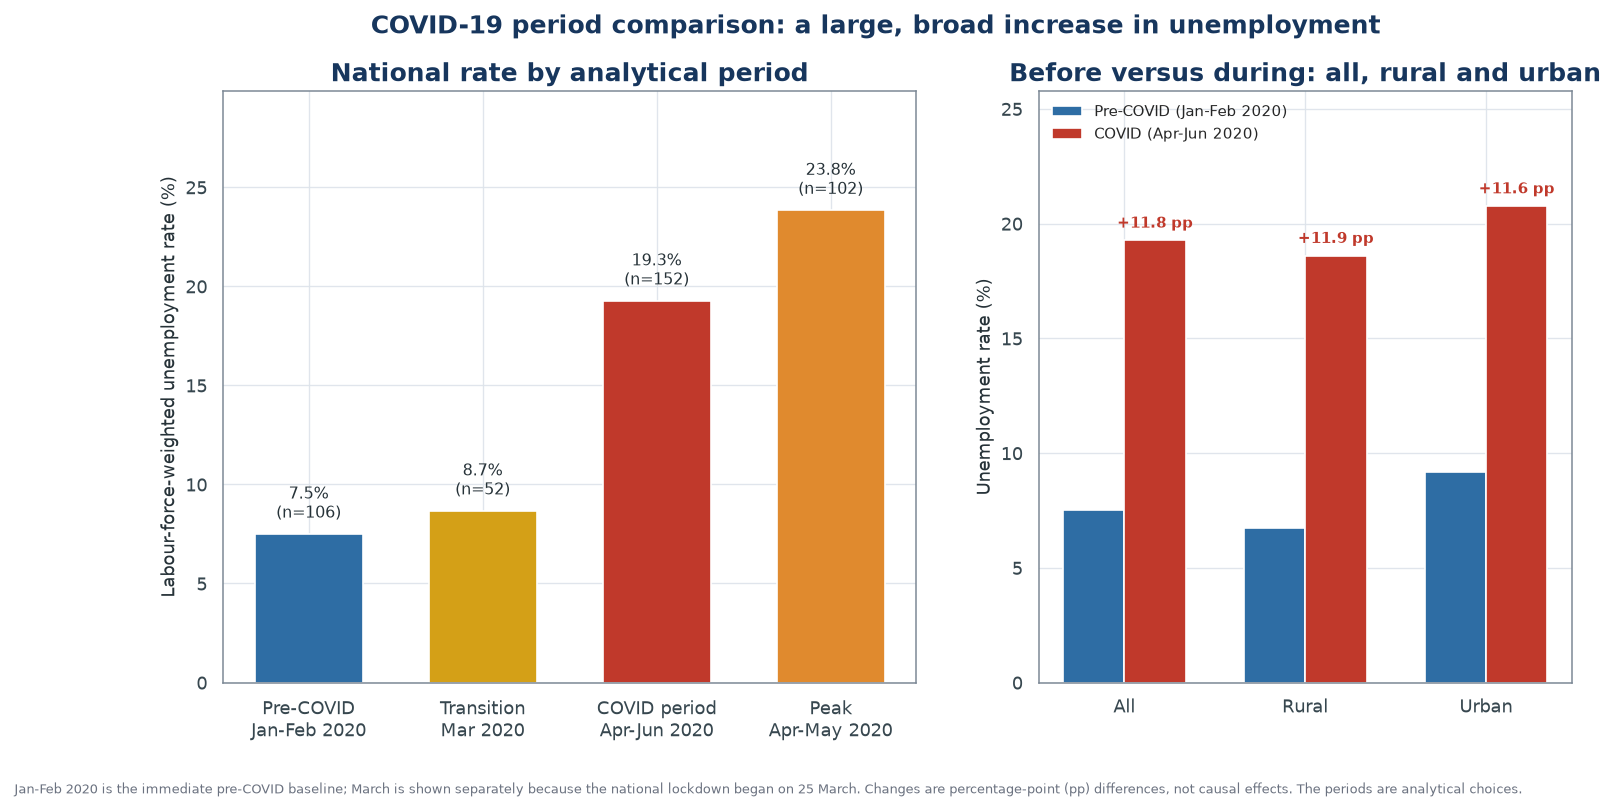

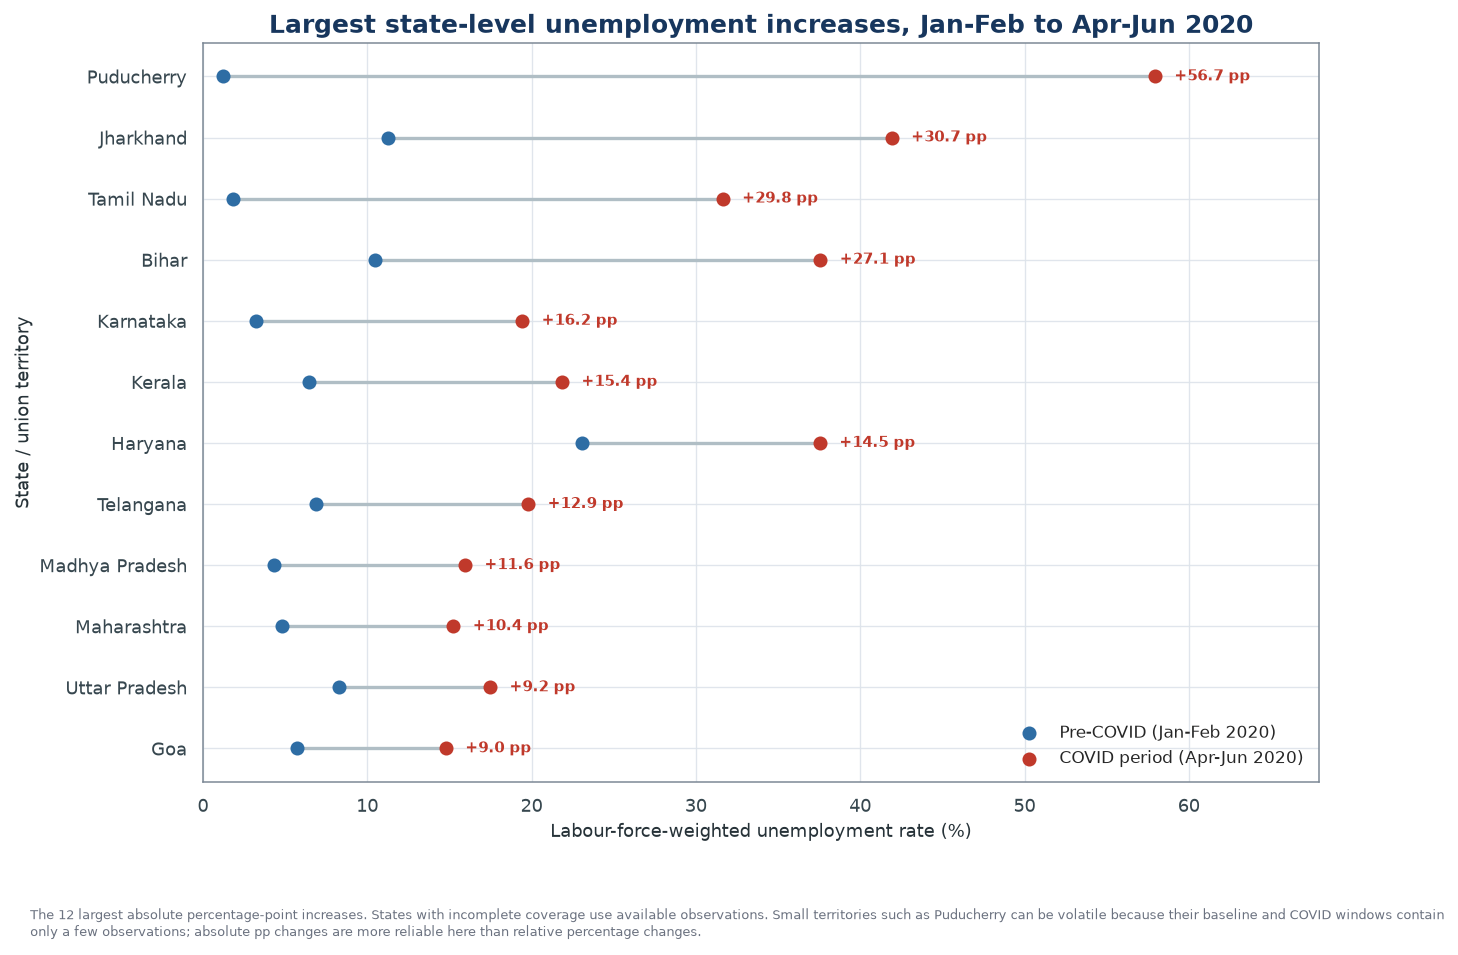

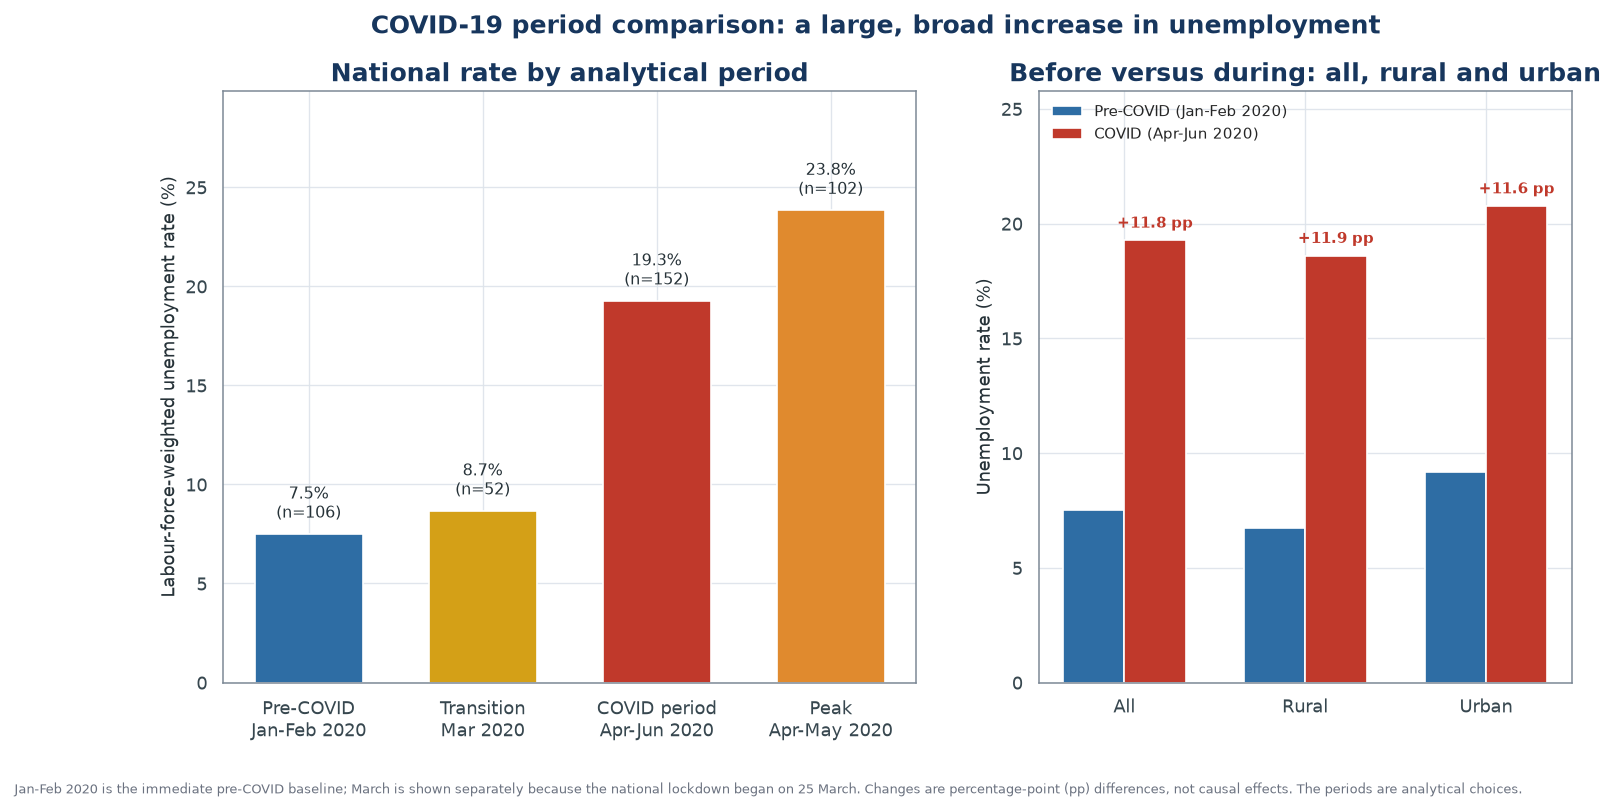

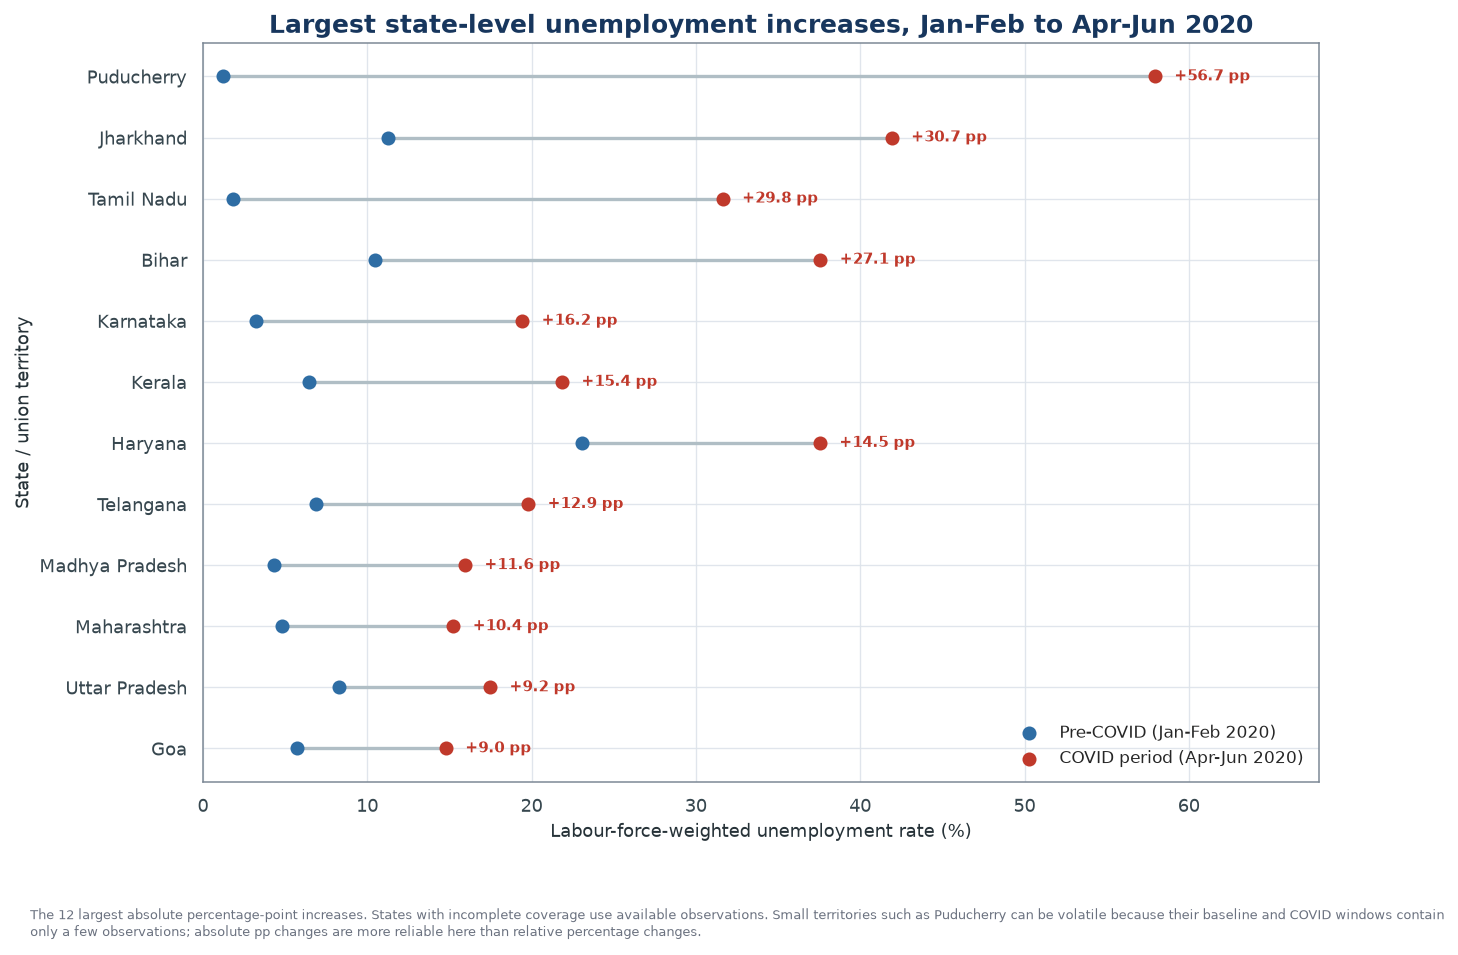

In [16]:
fig = charts.plot_covid_period_comparison(df1)
display(fig)

fig = charts.plot_covid_state_increases(df1)
display(fig)

The bar chart makes the scale explicit: the COVID-period rate is more than 2.5 times
the immediate baseline, and the April-May window is over three times baseline. The
right panel shows that the shock is broad-based, not solely an urban phenomenon.
The dumbbell chart ranks absolute state increases. Small territories such as
Puducherry need cautious interpretation because their estimates are volatile.

In [17]:
d2_monthly_rows = []
for month, group in df2.groupby("month_start", sort=True):
    d2_monthly_rows.append(
        {
            "month": group["month"].iloc[0],
            "n_states": group["region"].nunique(),
            "weighted_rate": utils.weighted_rate(group),
            "unweighted_rate": group["unemployment_rate"].mean(),
            "total_employed_millions": group["estimated_employed"].sum() / 1e6,
            "average_lpr": group["labour_participation_rate"].mean(),
        }
    )
d2_monthly = pd.DataFrame(d2_monthly_rows)
display(d2_monthly.round(2))

common_states = sorted(
    set(df2.loc[df2["month"] == "2020-01", "region"])
    & set(df2.loc[df2["month"] == "2020-10", "region"])
)
common = df2[
    (df2["region"].isin(common_states))
    & (df2["month"].isin(["2020-01", "2020-10"]))
]
common_summary = []
for month_name, group in common.groupby("month"):
    common_summary.append(
        {
            "month": month_name,
            "weighted_rate": utils.weighted_rate(group),
            "employed_millions": group["estimated_employed"].sum() / 1e6,
            "average_lpr": group["labour_participation_rate"].mean(),
        }
    )
common_summary = pd.DataFrame(common_summary).set_index("month")
display(common_summary.round(2))
print("Common states:", len(common_states))

,month,n_states,weighted_rate,unweighted_rate,total_employed_millions,average_lpr
0,2020-01,26,7.22,9.20,406.57,44.63
1,2020-02,26,7.77,9.27,402.69,44.18
2,2020-03,27,8.76,10.78,392.54,43.75
3,2020-04,26,23.95,22.24,274.83,35.30
4,2020-05,27,21.83,23.24,310.70,39.65
5,2020-06,27,10.23,10.91,374.15,41.20
6,2020-07,27,7.43,9.83,389.29,42.27
7,2020-08,27,8.36,10.31,389.58,42.39
8,2020-09,27,6.71,8.71,393.87,41.97
9,2020-10,27,7.01,8.03,393.66,41.44


,weighted_rate,employed_millions,average_lpr
month,,,
2020-01,7.22,406.57,44.63
2020-10,7.01,393.42,41.41


Common states: 26


### Longer 2020 view (supplementary dataset)

Dataset 2 extends the picture to October 2020. The weighted rate rises from
**7.22% in January** to
**23.95% in April**, then falls
to **7.01% in October**.

Comparing the same 26 states in January and October:
the rate is **-0.21 pp**, but employment
is **-3.2%** lower and LPR is
**-3.21 pp** lower. The headline unemployment rate
has returned to its pre-shock level, but the labour market has not fully recovered:
fewer people are employed and fewer are participating.

This is a crucial distinction. A falling unemployment rate can reflect people
leaving the labour force rather than finding jobs.

In [18]:
zone_rows = []
baseline2 = period_subset(df2, "2020-01-01", "2020-02-29")
crisis2 = period_subset(df2, "2020-04-01", "2020-06-30")
for zone in sorted(df2["zone"].unique()):
    all_zone = df2[df2["zone"] == zone]
    pre = baseline2[baseline2["zone"] == zone]
    during = crisis2[crisis2["zone"] == zone]
    zone_rows.append(
        {
            "zone": zone,
            "states": all_zone["region"].nunique(),
            "weighted_rate": utils.weighted_rate(all_zone),
            "baseline": utils.weighted_rate(pre),
            "covid": utils.weighted_rate(during),
            "change_pp": utils.weighted_rate(during) - utils.weighted_rate(pre),
        }
    )
display(pd.DataFrame(zone_rows).sort_values("weighted_rate", ascending=False).round(2))

# Schema comparison, not a merge: D1 derived overall rate vs D2 rate.
d1_state_month = []
for (region, month), group in df1.groupby(["region", "month"]):
    d1_state_month.append(
        {"region": region, "month": month, "d1_weighted_rate": utils.weighted_rate(group)}
    )
comparison = (
    pd.DataFrame(d1_state_month)
    .merge(df2[["region", "month", "unemployment_rate"]], on=["region", "month"])
    .rename(columns={"unemployment_rate": "d2_rate"})
)
comparison["difference_pp"] = comparison["d1_weighted_rate"] - comparison["d2_rate"]
print("Overlap comparison rows:", len(comparison))
print("Pearson correlation:", round(comparison["d1_weighted_rate"].corr(comparison["d2_rate"]), 3))
print("Mean difference (pp):", round(comparison["difference_pp"].mean(), 3))
print("Mean absolute difference (pp):", round(comparison["difference_pp"].abs().mean(), 3))
display(comparison.head())

,zone,states,weighted_rate,baseline,covid,change_pp
0,East,4,13.59,7.48,25.11,17.63
1,North,8,13.46,11.71,18.39,6.68
3,South,6,8.54,4.30,18.65,14.35
2,Northeast,4,7.29,8.03,9.82,1.78
4,West,5,7.05,5.39,13.04,7.65


Overlap comparison rows: 158
Pearson correlation: 0.972
Mean difference (pp): 0.253
Mean absolute difference (pp): 1.044


,region,month,d1_weighted_rate,d2_rate,difference_pp
0,Andhra Pradesh,2020-01,5.48,5.48,0.00
1,Andhra Pradesh,2020-02,5.84,5.83,0.01
2,Andhra Pradesh,2020-03,5.79,5.79,0.00
3,Andhra Pradesh,2020-04,20.51,20.51,-0.00
4,Andhra Pradesh,2020-05,17.50,17.43,0.07


### Geographic zones and dataset validation

The supplementary zone averages are **East 13.59%**,
**North 13.46%**, **South 8.54%**,
**Northeast 7.29%** and
**West 7.05%**. The East and North have the highest
average levels; the East also has the largest increase (+17.63 pp). These zone
numbers aggregate very different states and are descriptive only.

The overlap check compares 158 state-month pairs without
merging. The Pearson correlation is **0.972** and the
mean signed difference is **+0.25 pp**, but the mean
absolute difference is **1.04 pp** and the
maximum is **20.08 pp**. The derived weighted
measure is broadly consistent with Dataset 2, but the discrepancies are why the files
should not be treated as interchangeable.

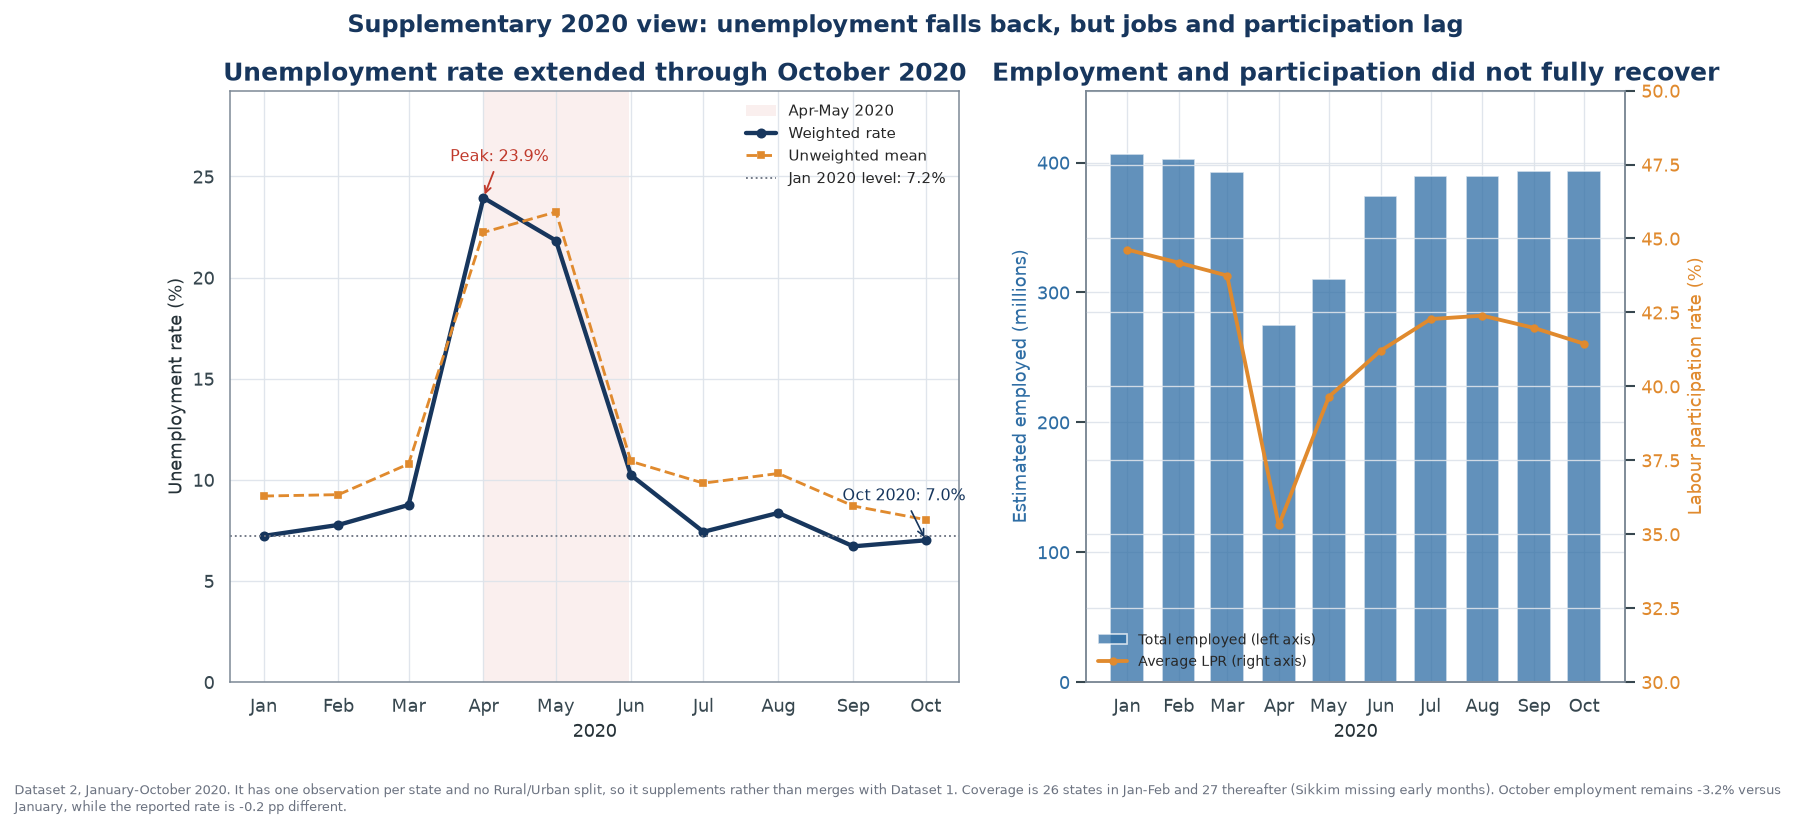

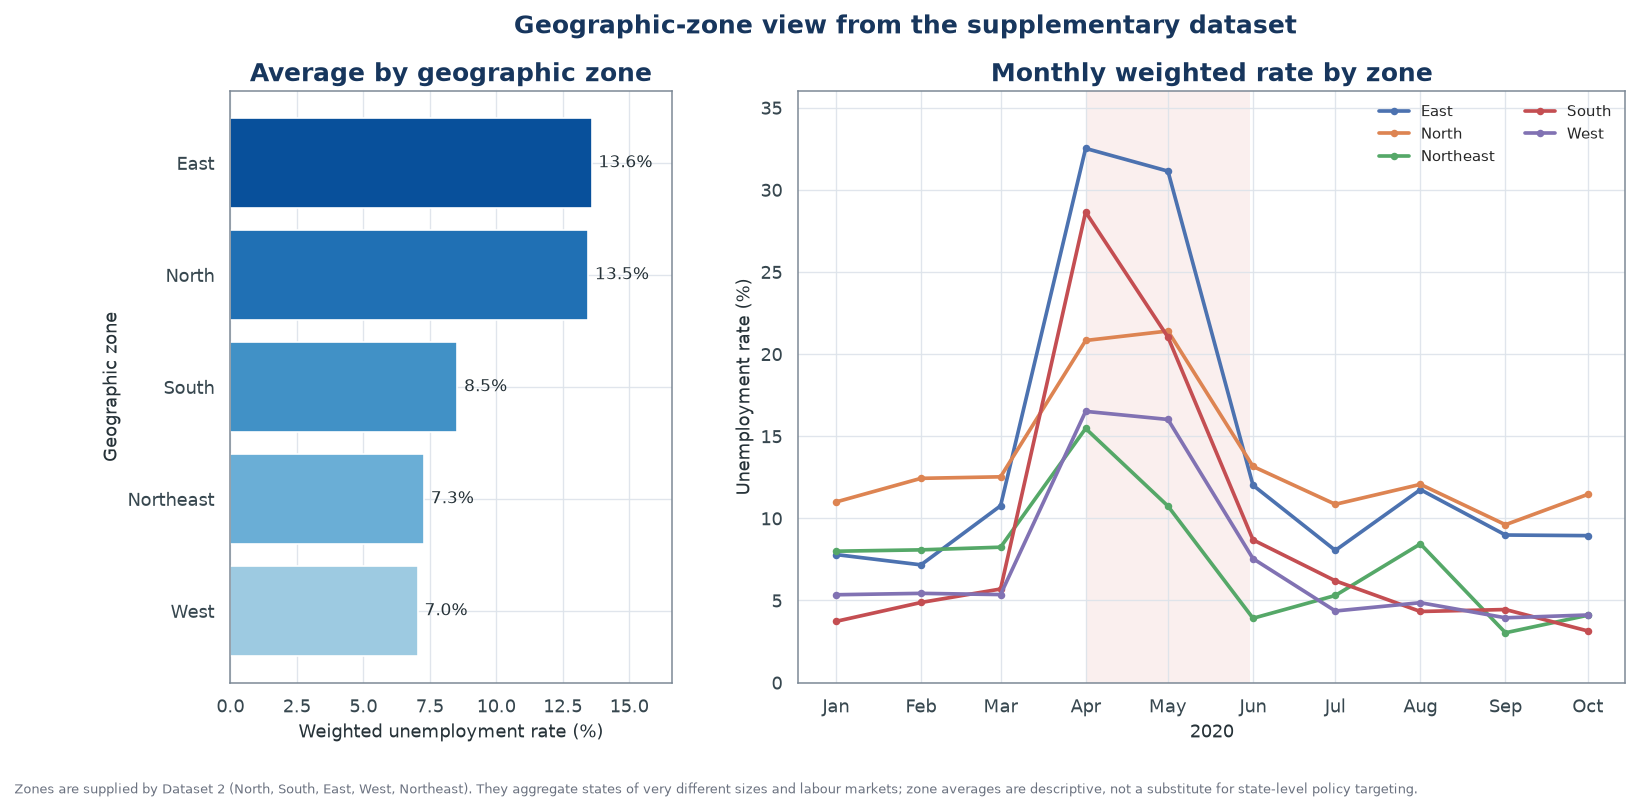

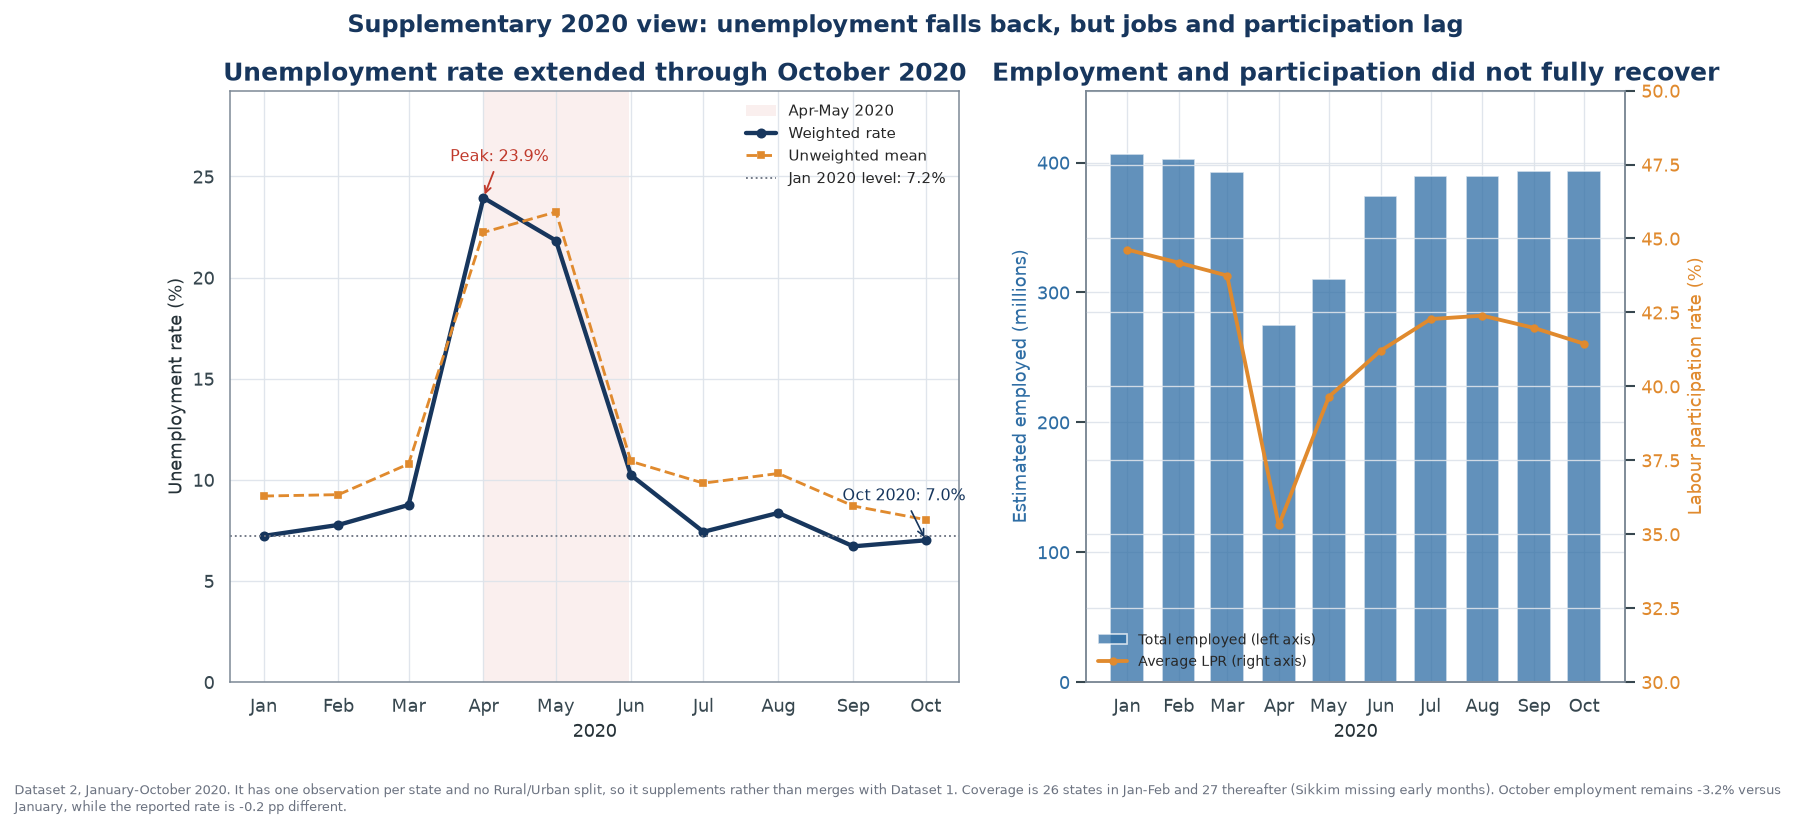

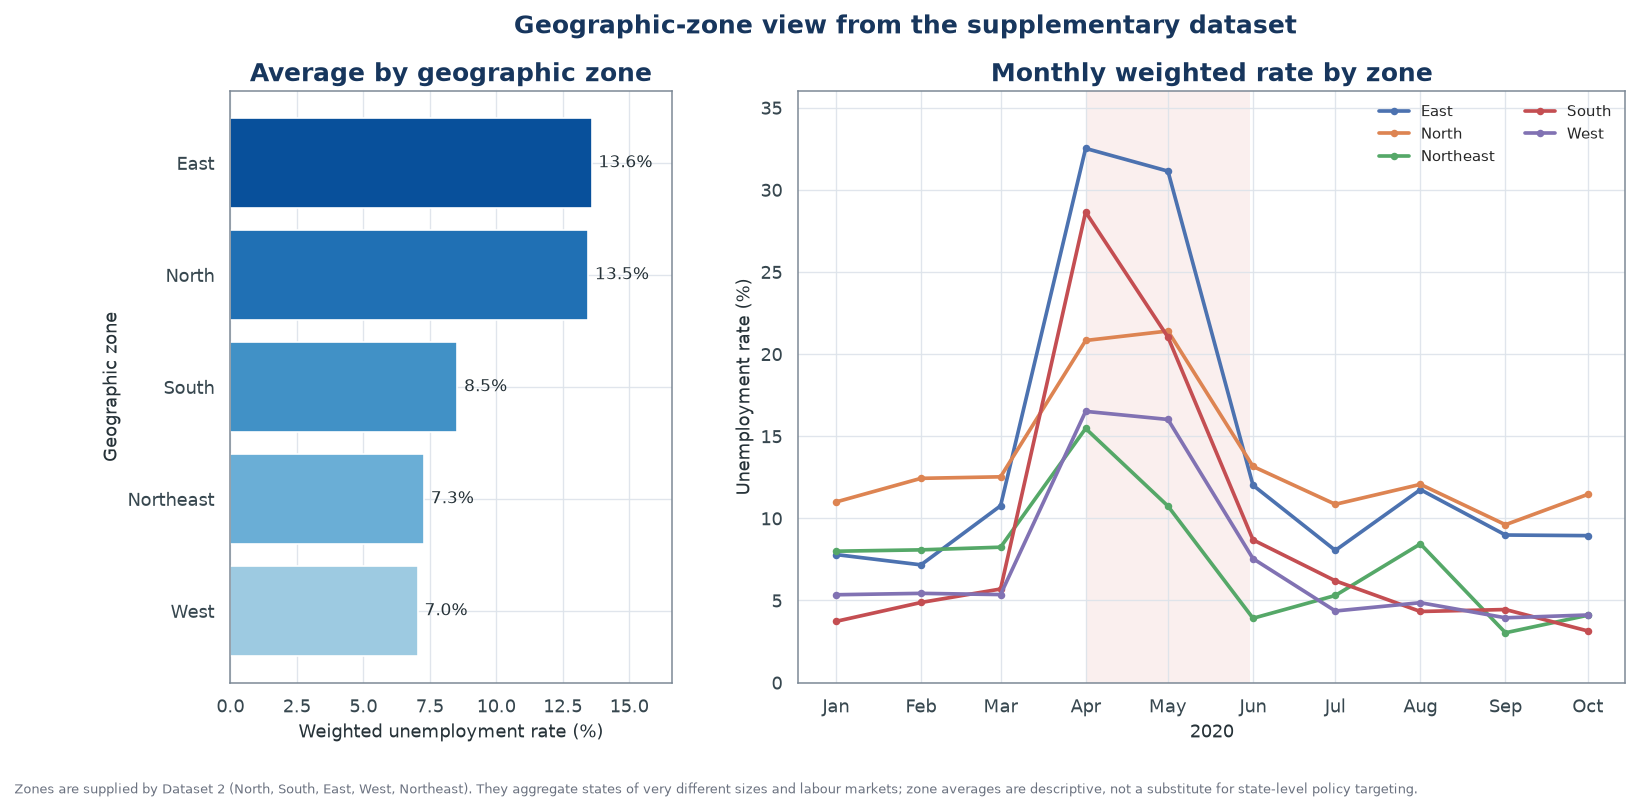

In [19]:
fig = charts.plot_extended_recovery_d2(df2)
display(fig)

fig = charts.plot_zone_unemployment(df2)
display(fig)

## 7. Patterns, seasonality and causal caution

### What the monthly data show

- A stable pre-COVID band around 7-8% weighted.
- A sharp spike in April-May 2020.
- A large but partial fall in June 2020.
- A return of the headline rate to near its January 2020 level by October 2020 in
  Dataset 2, while employment and participation remain below January.
- Strong cross-state heterogeneity in both level and timing.

### Seasonality

The 14-month primary dataset is **too short** to establish a seasonal cycle. Only
**May and June** occur in both 2019 and 2020, and the 2020 observations coincide with
the COVID shock. Dataset 2 covers only one calendar year. No seasonal claim is made.
A proper seasonal analysis would need several complete years and a model that
separates season, trend and shock.

In [20]:
calendar = pd.read_csv(utils.ANALYSIS_DIR / "calendar_month_summary.csv")
display(calendar.round(2))
print("Months observed in both years:", (calendar["n_years"] >= 2).sum())
print("Primary dataset months:", df1["month"].nunique())

,month_number,month_name,years_covered,n_years,n_obs,weighted_rate,unweighted_rate
0,1,Jan,[2020],1,53,7.24,9.95
1,2,Feb,[2020],1,53,7.78,9.96
2,3,Mar,[2020],1,52,8.67,10.70
3,4,Apr,[2020],1,51,24.16,23.64
4,5,May,"[2019, 2020]",2,105,14.92,16.65
5,6,Jun,"[2019, 2020]",2,104,9.43,10.55
6,7,Jul,[2019],1,54,7.37,9.03
7,8,Aug,[2019],1,53,8.08,9.64
8,9,Sep,[2019],1,52,7.08,9.05
9,10,Oct,[2019],1,55,8.11,9.90


Months observed in both years: 2
Primary dataset months: 14


### Causal caution

The analysis documents a sharp change that coincides with the COVID-19 period. It
**cannot prove that COVID-19 alone caused it**. There is no counterfactual and no
control group. Lockdowns, migration, survey disruption, fiscal support, global
demand and measurement changes all moved at the same time. Before-and-after
comparisons are descriptive; credible causal estimates would require a research
design beyond this dataset.

## 8. Key findings

1. **Unemployment was structurally uneven before COVID.** The 14-month weighted
   national average is **9.94%**, but state averages range
   from **3.17% in Meghalaya** to
   **28.04% in Tripura**.
2. **Urban areas had higher unemployment but rural areas had higher participation.**
   Urban weighted unemployment is 11.18% versus
   9.36% rural; average LPR is 44.46% rural
   versus 40.90% urban.
3. **The COVID-period increase was very large.** The weighted rate rose
   **+11.77 pp** from the Jan-Feb 2020 baseline to
   Apr-Jun 2020, a **156.8%** relative increase.
   The Apr-May peak was **23.85%**.
4. **The shock was broad-based across rural and urban areas.** Rural rose
   **+11.89 pp (176.9%)**; urban rose
   **+11.58 pp (126.1%)**.
5. **Employment fell much more than the unemployment rate alone suggests.**
   In the balanced 20-state panel, April employment fell
   **121.0 million
   (-31.5%)** from the Jan-Feb average.
   June was still 8.0% below baseline.
6. **The October recovery is incomplete.** In the same 26 states, Dataset 2 shows
   the rate **-0.21 pp** versus January,
   but employment **-3.2%** lower and LPR
   **-3.21 pp** lower.
7. **The shock was regionally concentrated.** Jharkhand, Tamil Nadu and Bihar had
   some of the largest absolute increases; East and North zones have the highest
   average levels. Small territories such as Puducherry show extreme volatility.
8. **Seasonality cannot be established.** Only two calendar months repeat across
   years, and those repeats are contaminated by the COVID shock.

### What the data do not show

- They do not identify causal effects of lockdowns or COVID-19.
- They do not provide age, gender, industry, education or district detail.
- They cannot distinguish unemployment from underemployment or informal work.
- They do not measure income loss, poverty or migration.
- Dataset 2 is not directly comparable to Dataset 1 at all times and is not merged.

## 9. Policy recommendations linked to findings

These recommendations follow from the observed patterns. They are not claims that a
particular intervention has been evaluated in this dataset.

### 9.1 Protect rural employment and earnings

Rural unemployment rose **+11.89 pp** (from
6.72% to 18.61%), a
**176.9%** relative increase, even though rural areas had higher
participation. Expand guaranteed rural employment, irrigation, rural infrastructure,
agri-processing and local food supply chains. These measures can stabilise earnings
when urban migration reverses and rural labour supply rises.

### 9.2 Support urban job recovery and re-entry

Urban unemployment was the highest average level before the shock
(11.18%) and remained higher during it
(20.77%). Urban LPR fell by
**6.5 pp** in the COVID window. Prioritise MSME credit,
wage support in contact-intensive services, safe transport and childcare, and
job-search/re-entry services for displaced urban workers.

### 9.3 Target the highest-burden and largest-shock states

High average unemployment states (**Tripura 28.04%**,
**Haryana 26.04%**, **Jharkhand 17.74%**,
**Bihar 17.34%**, **Delhi 17.05%**)
need structural employment programmes. The largest observed increases were in
**Puducherry, Jharkhand, Tamil Nadu, Bihar and Karnataka**; however, Puducherry's
baseline was unusually low and volatile, so packages should be designed with
state-specific diagnostics rather than a single formula.

### 9.4 Rebuild jobs, not just the unemployment rate

April employment loss in the balanced panel was
**121 million jobs
(-31.5%)**, and June remained
**8.0%** below baseline. Wage
subsidies, hiring incentives, public works and MSME credit should be judged by
employment restoration, not only by a falling unemployment rate.

### 9.5 Support labour-force participation

The national LPR fell roughly **7 pp** in April, and the supplementary data still
show a **3.21 pp** participation gap in
October for the same 26 states. Childcare, safe public transport, formalisation of
informal work, portable benefits and accessible job-search support can help people
return to the labour force. A low unemployment rate caused by discouraged workers
leaving the labour force is not a healthy recovery.

### 9.6 Strengthen social protection for informal workers

The scale and speed of the employment loss - over 100 million jobs in the balanced
panel in April and May - imply that shock-responsive income support is essential.
Portable unemployment benefits, food support, direct cash transfers and informal-worker
registration would reduce distress and prevent asset sales. Targeting should use the
state and area patterns documented here.

### 9.7 Invest in data and evaluation

The analysis is limited by 14 months of primary data, missing region-months,
inconsistent small-area estimates and no demographic detail. Policymakers should
publish timely state-district-month estimates with age, gender and sector breakdowns,
and evaluate interventions against pre-specified comparison groups. Better data would
allow seasonal adjustment and causal evaluation rather than descriptive before-after
comparisons.

## 10. Limitations

- **Short primary panel:** 14 months cannot establish seasonality or long-run trends.
- **No causal identification:** before-and-after changes are not causal effects.
- **Survey estimates:** the CSVs do not document sampling design, revisions or
  definitions; values should be treated as estimates.
- **Missing observations:** 44 region-area-months in Dataset 1 and 3 region-months in
  Dataset 2 are absent. No values were imputed.
- **Small-area volatility:** Puducherry, Chandigarh and other small territories have
  very few observations and extreme rates.
- **Aggregation:** zone, state and national averages hide district and household
  heterogeneity.
- **No demographic detail:** age, gender, education, industry and informal-work status
  are unavailable, limiting targeted policy design.
- **Two datasets, two populations:** Dataset 1 and Dataset 2 are related but not
  identical; they are compared only where definitions overlap.
- **Measurement of employment:** estimated employed counts are model-based and may
  not capture underemployment or income loss.

## 11. Conclusion

The data describe a labour market that was already uneven before the pandemic and
then experienced an extraordinary, broad-based shock. The labour-force-weighted
national unemployment rate rose from **7.51%**
in January-February 2020 to **19.28%** in
April-June 2020, with an April-May peak of **23.85%**.
Employment in a balanced 20-state panel fell by nearly a third in April.

By October 2020, the supplementary data show the headline unemployment rate back near
its January level, but employment and participation had not recovered. That gap is the
central policy message: **a lower unemployment rate is not the same as a restored
labour market.** Rural areas need earnings and employment support; urban areas need
job recovery and re-entry support; high-burden and high-shock states need targeted
programmes; and informal workers need shock-responsive social protection.

The analysis is descriptive and limited by data availability. Its value lies in
making the scale, unevenness and incomplete recovery visible - and in linking each
recommendation to a measured pattern rather than to assumption.

## Reproducibility

From the project root:

```bash
python src/01_dataset_inspection.py
python src/02_data_cleaning.py
python src/03_exploratory_analysis.py
python src/04_data_visualization.py
python src/05_covid_impact_analysis.py
python src/06_generate_report.py
```

Key outputs:

- Clean data: `outputs/cleaned_data/`
- Charts: `outputs/charts/` (14 PNG files)
- Tables and JSON: `outputs/analysis/`
- Inspection report: `outputs/inspection/`
- PDF report: `report/Unemployment_Analysis_Report.pdf`

Data source: the two CSV files supplied for the CodeAlpha Task 2 exercise. No
external data or invented statistics are used.